# Лабораторна робота 5-6: Нейронна мережа і регуляризація

**Датасет:** FashionMNIST — 70 000 зображень одягу $28 \times 28$, 10 класів.

**Мета:** реалізувати повнозв'язну нейронну мережу (MLP) з нуля на NumPy, перевірити зворотне поширення помилки чисельним диференціюванням, реалізувати збереження та відновлення ваг, а також експериментально дослідити вплив L1, L2, Dropout, weight clipping і gradient clipping на розподіл ваг, розрідженість, мертві нейрони та якість класифікації.

**Індивідуальний варіант:** номер у списку групи $N = 4$, отже $\text{SEED} = 42 + 4 = 46$.

**Структура ноутбука** повторює методичку: Блок 1 (розд. 2), Блок 2 (розд. 3), аналіз і порівняння (розд. 4), далі висновок. Прямий прохід, backpropagation та оптимізатор написано вручну, без `autograd` і готових нейромереж; scikit-learn використано лише для стратифікованого поділу даних.


## Імпорт бібліотек і фіксація параметрів


In [1]:
import os

os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['VECLIB_MAXIMUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'

import gzip
import hashlib
import json
import tempfile
import time
import urllib.request
from dataclasses import dataclass
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
from IPython.display import display
from joblib import Parallel, delayed
from scipy import stats
from sklearn.model_selection import train_test_split

STUDENT_NUMBER = 4
SEED = 42 + STUDENT_NUMBER
SEEDS = [SEED, SEED + 1, SEED + 2]
N_JOBS = min(8, os.cpu_count() or 1)

HIDDEN_SIZES = (256, 128, 64)
LEARNING_RATE = 0.1
LEARNING_RATE_DROP_EPOCH = 20
LEARNING_RATE_DROP_FACTOR = 0.1
BATCH_SIZE = 64
EPOCHS = 30
VALIDATION_SIZE = 10_000
TRAIN_SUBSET_SIZE = None
SPARSITY_THRESHOLD = 0.01
INFERENCE_BATCH = 4096

MAIN_COLOR = '#2a78d6'
ACCENT_COLOR = '#eb6834'
THIRD_COLOR = '#1baf7a'
NEUTRAL_COLOR = '#8a8984'

np.random.seed(SEED)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (8, 4.5)

print('SEED =', SEED, '| повторні запуски:', SEEDS)
for module in [np, pd, matplotlib, sklearn, scipy, joblib]:
    print(f'{module.__name__:12s} {module.__version__}')


SEED = 46 | повторні запуски: [46, 47, 48]
numpy        2.4.6
pandas       3.1.1
matplotlib   3.11.2
sklearn      1.9.1
scipy        1.17.1
joblib       1.6.0


## Дані

Архіви завантажуються з офіційного репозиторію FashionMNIST, цілісність перевіряється за MD5 із його документації. Пікселі переводяться у вектори довжини $28 \cdot 28 = 784$ і нормалізуються до $[0, 1]$.

Офіційний тренувальний набір (60 000) стратифіковано поділено на train (50 000) і validation (10 000). Коефіцієнти регуляризації обираються лише за validation, а test (10 000) використовується один раз, наприкінці роботи. Всі експерименти використовують одні й ті самі підмножини.


,Вибірка,Об'єктів,Ознак,Мін. пікселя,Макс. пікселя,Об'єктів у найменшому класі,Об'єктів у найбільшому класі
0,train,50000,784,0.0,1.0,5000,5000
1,validation,10000,784,0.0,1.0,1000,1000
2,test,10000,784,0.0,1.0,1000,1000


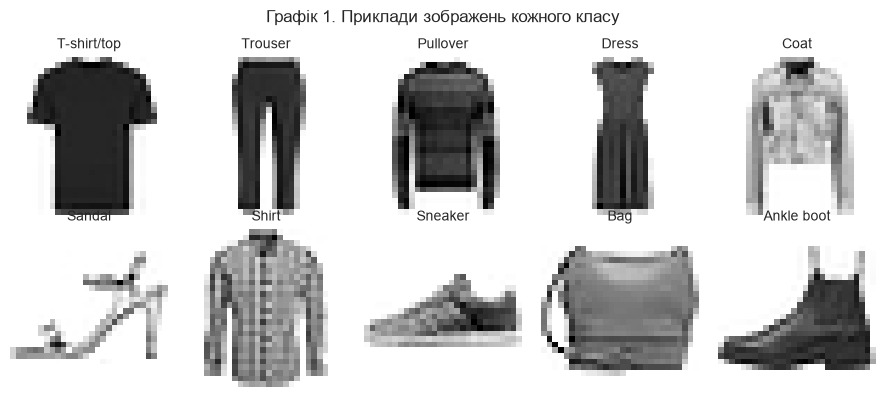

In [2]:
DATA_DIR = Path('data')
DATA_URL = 'https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/'
DATA_FILES = {
    'train-images-idx3-ubyte.gz': '8d4fb7e6c68d591d4c3dfef9ec88bf0d',
    'train-labels-idx1-ubyte.gz': '25c81989df183df01b3e8a0aad5dffbe',
    't10k-images-idx3-ubyte.gz': 'bef4ecab320f06d8554ea6380940ec79',
    't10k-labels-idx1-ubyte.gz': 'bb300cfdad3c16e7a12a480ee83cd310',
}
CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


def ensure_file(name: str, expected_md5: str) -> Path:
    path = DATA_DIR / name
    if not path.exists():
        DATA_DIR.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, path)
    actual_md5 = hashlib.md5(path.read_bytes()).hexdigest()
    if actual_md5 != expected_md5:
        raise ValueError(f'{name}: очікувався MD5 {expected_md5}, отримано {actual_md5}')
    return path


def read_images(path: Path) -> np.ndarray:
    with gzip.open(path, 'rb') as handle:
        return np.frombuffer(handle.read(), dtype=np.uint8, offset=16).reshape(-1, 784) / 255.0


def read_labels(path: Path) -> np.ndarray:
    with gzip.open(path, 'rb') as handle:
        return np.frombuffer(handle.read(), dtype=np.uint8, offset=8).astype(np.int64)


paths = {name: ensure_file(name, md5) for name, md5 in DATA_FILES.items()}
X_pool = read_images(paths['train-images-idx3-ubyte.gz'])
y_pool = read_labels(paths['train-labels-idx1-ubyte.gz'])
X_test = read_images(paths['t10k-images-idx3-ubyte.gz'])
y_test = read_labels(paths['t10k-labels-idx1-ubyte.gz'])

X_train, X_val, y_train, y_val = train_test_split(
    X_pool, y_pool, test_size=VALIDATION_SIZE, stratify=y_pool, random_state=SEED
)
if TRAIN_SUBSET_SIZE is not None:
    X_train, y_train = X_train[:TRAIN_SUBSET_SIZE], y_train[:TRAIN_SUBSET_SIZE]

display(pd.DataFrame({
    'Вибірка': ['train', 'validation', 'test'],
    'Об\'єктів': [len(y_train), len(y_val), len(y_test)],
    'Ознак': [X_train.shape[1], X_val.shape[1], X_test.shape[1]],
    'Мін. пікселя': [X_train.min(), X_val.min(), X_test.min()],
    'Макс. пікселя': [X_train.max(), X_val.max(), X_test.max()],
    'Об\'єктів у найменшому класі': [np.bincount(part).min() for part in (y_train, y_val, y_test)],
    'Об\'єктів у найбільшому класі': [np.bincount(part).max() for part in (y_train, y_val, y_test)],
}))

fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for class_index, axis in enumerate(axes.ravel()):
    example = X_train[np.argmax(y_train == class_index)]
    axis.imshow(example.reshape(28, 28), cmap='gray_r')
    axis.set_title(CLASS_NAMES[class_index], fontsize=10)
    axis.axis('off')
fig.suptitle('Графік 1. Приклади зображень кожного класу')
plt.tight_layout()
plt.show()


## Блок 1. Реалізація нейронної мережі з нуля

### 2.1–2.3. Архітектура, прямий прохід і backpropagation

Архітектура: **784 → 256 → 128 → 64 → 10** (3 приховані шари, ReLU), вихідний шар Softmax, функція втрат categorical cross-entropy, оптимізатор SGD, ініціалізація He.

Клас `MLP` зберігає матриці ваг, вектори зміщень, проміжні значення $Z^{(l)}$ та $A^{(l)}$ і параметри архітектури. Основа `forward` і `backward` відповідає методичці. Є два доповнення для Dropout:

- $Z^{(l)}$ залишається передактивацією до маски, а в `activations` потрапляє вже $\widetilde{A}^{(l)} = A^{(l)} \odot M / (1-p)$, тобто вхід наступного шару;
- у `backward` градієнт множиться не лише на $f'(Z^{(l)})$, а й на $M/(1-p)$. Без цього множника обчислений градієнт не відповідав би функції, яку насправді рахує мережа під час навчання.

Під час inference (`training=False`, режим за замовчуванням) Dropout вимкнено.


In [3]:
INITIALIZERS = {
    'he': lambda rng, n_in, n_out: rng.normal(0.0, np.sqrt(2.0 / n_in), (n_in, n_out)),
    'xavier': lambda rng, n_in, n_out: rng.uniform(
        -np.sqrt(6.0 / (n_in + n_out)), np.sqrt(6.0 / (n_in + n_out)), (n_in, n_out)
    ),
}


class MLP:
    def __init__(self, layer_sizes: tuple[int, ...], seed: int, dropout_p: float = 0.0, init_method: str = 'he') -> None:
        if len(layer_sizes) < 2:
            raise ValueError('Мережа має містити принаймні вхідний і вихідний шари')
        if not 0.0 <= dropout_p < 1.0:
            raise ValueError(f'dropout_p має належати [0, 1), отримано {dropout_p}')
        if init_method not in INITIALIZERS:
            raise ValueError(f'Невідомий метод ініціалізації: {init_method}')
        self.layer_sizes = tuple(int(size) for size in layer_sizes)
        self.seed = int(seed)
        self.dropout_p = float(dropout_p)
        self.init_method = init_method
        self.num_layers = len(self.layer_sizes) - 1
        init_rng = np.random.default_rng([self.seed, 0])
        self.weights = [
            INITIALIZERS[init_method](init_rng, n_in, n_out)
            for n_in, n_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:])
        ]
        self.biases = [np.zeros(n_out) for n_out in self.layer_sizes[1:]]
        self.dropout_rng = np.random.default_rng([self.seed, 1])
        self.activations = []
        self.z_values = []
        self.dropout_masks = []

    def forward(self, X: np.ndarray, training: bool = False) -> np.ndarray:
        self.activations = [X]
        self.z_values = []
        self.dropout_masks = []
        apply_dropout = training and self.dropout_p > 0.0

        A = X
        for W, b in zip(self.weights[:-1], self.biases[:-1]):
            Z = A @ W + b
            A = np.maximum(0, Z)
            if apply_dropout:
                keep = self.dropout_rng.random(A.shape) >= self.dropout_p
                mask = keep / (1.0 - self.dropout_p)
                A = A * mask
                self.dropout_masks.append(mask)
            self.z_values.append(Z)
            self.activations.append(A)

        Z = A @ self.weights[-1] + self.biases[-1]
        Z = Z - np.max(Z, axis=1, keepdims=True)
        exp_Z = np.exp(Z)
        P = exp_Z / np.sum(exp_Z, axis=1, keepdims=True)
        self.z_values.append(Z)
        self.activations.append(P)
        return P

    def backward(self, y_true: np.ndarray) -> tuple[list[np.ndarray], list[np.ndarray]]:
        n = y_true.shape[0]
        grads_W = [None] * self.num_layers
        grads_b = [None] * self.num_layers

        delta = self.activations[-1].copy()
        delta[np.arange(n), y_true] -= 1
        delta /= n

        for l in reversed(range(self.num_layers)):
            A_prev = self.activations[l]
            grads_W[l] = A_prev.T @ delta
            grads_b[l] = np.sum(delta, axis=0)
            if l > 0:
                delta = delta @ self.weights[l].T
                delta = delta * (self.z_values[l - 1] > 0)
                if self.dropout_masks:
                    delta = delta * self.dropout_masks[l - 1]
        return grads_W, grads_b

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        batches = [self.forward(X[start:start + INFERENCE_BATCH]) for start in range(0, len(X), INFERENCE_BATCH)]
        return np.vstack(batches)

    def config(self) -> dict:
        return {
            'layer_sizes': list(self.layer_sizes),
            'seed': self.seed,
            'dropout_p': self.dropout_p,
            'init_method': self.init_method,
        }

    def save_weights(self, path: Path) -> None:
        data = {'config': np.array(json.dumps(self.config()))}
        for i, W in enumerate(self.weights):
            data[f'W_{i}'] = W
        for i, b in enumerate(self.biases):
            data[f'b_{i}'] = b
        np.savez(path, **data)

    def load_weights(self, path: Path) -> None:
        with np.load(path, allow_pickle=False) as data:
            saved_config = json.loads(str(data['config']))
            if tuple(saved_config['layer_sizes']) != self.layer_sizes:
                raise ValueError(
                    f"Архітектура файлу {saved_config['layer_sizes']} не збігається з {list(self.layer_sizes)}"
                )
            self.weights = [data[f'W_{i}'] for i in range(self.num_layers)]
            self.biases = [data[f'b_{i}'] for i in range(self.num_layers)]

    @classmethod
    def from_file(cls, path: Path) -> 'MLP':
        with np.load(path, allow_pickle=False) as data:
            saved_config = json.loads(str(data['config']))
        model = cls(**saved_config)
        model.load_weights(path)
        return model


LAYER_SIZES = (X_train.shape[1], *HIDDEN_SIZES, len(CLASS_NAMES))
demo_model = MLP(LAYER_SIZES, SEED)
demo_probabilities = demo_model.forward(X_train[:5])

display(pd.DataFrame({
    'Шар': [f'{index + 1}' for index in range(demo_model.num_layers)],
    'Розмір W': [str(W.shape) for W in demo_model.weights],
    'Розмір b': [str(b.shape) for b in demo_model.biases],
    'Параметрів': [W.size + b.size for W, b in zip(demo_model.weights, demo_model.biases)],
    'Активація': ['ReLU'] * len(HIDDEN_SIZES) + ['Softmax'],
    'Std W за He': [round(float(W.std()), 4) for W in demo_model.weights],
    'Теоретичне sqrt(2/n_in)': [round(float(np.sqrt(2 / W.shape[0])), 4) for W in demo_model.weights],
}))
print('Усього параметрів:', sum(W.size + b.size for W, b in zip(demo_model.weights, demo_model.biases)))
print('Форма виходу forward:', demo_probabilities.shape, '| сума ймовірностей по рядках:', demo_probabilities.sum(axis=1).round(10))


,Шар,Розмір W,Розмір b,Параметрів,Активація,Std W за He,Теоретичне sqrt(2/n_in)
0,1,"(784, 256)","(256,)",200960,ReLU,0.0505,0.0505
1,2,"(256, 128)","(128,)",32896,ReLU,0.0887,0.0884
2,3,"(128, 64)","(64,)",8256,ReLU,0.1243,0.1250
3,4,"(64, 10)","(10,)",650,Softmax,0.1687,0.1768


Усього параметрів: 242762
Форма виходу forward: (5, 10) | сума ймовірностей по рядках: [1. 1. 1. 1. 1.]


### 2.4. Цикл навчання

Функція `fit` виконує кроки методички: перемішування, поділ на мінібатчі, прямий прохід, обчислення втрат, backpropagation, оновлення параметрів, оцінка на validation.

Порядок операцій на кроці: градієнт $L_{CE}$ → штраф L1/L2 (лише для $W$, зміщення не штрафуються) → gradient clipping за глобальною нормою всіх $W$ і $b$ → крок SGD → weight clipping. Для чесного порівняння `train_loss` і `val_loss` це завжди чиста cross-entropy в режимі inference, без штрафу й без Dropout.

**Вибір кроку навчання.** Пробні запуски зі сталим кроком ($\eta = 0.1$ і $\eta = 0.03$) дали сильні коливання якості між епохами: validation accuracy на останній епосі була на 2–2.5 в. п. нижчою за найкращу, і цей шум перекривав ефекти регуляризації. Тому використано той самий SGD (формули 25–26) зі ступінчастим кроком: $\eta = 0.1$ на епохах 1–20 і $\eta = 0.01$ на епохах 21–30, батч 64. Після зниження кроку коливання між епохами падають приблизно до 0.2 в. п., тому значення на останній епосі можна порівнювати. Цей розклад однаковий для всіх експериментів.


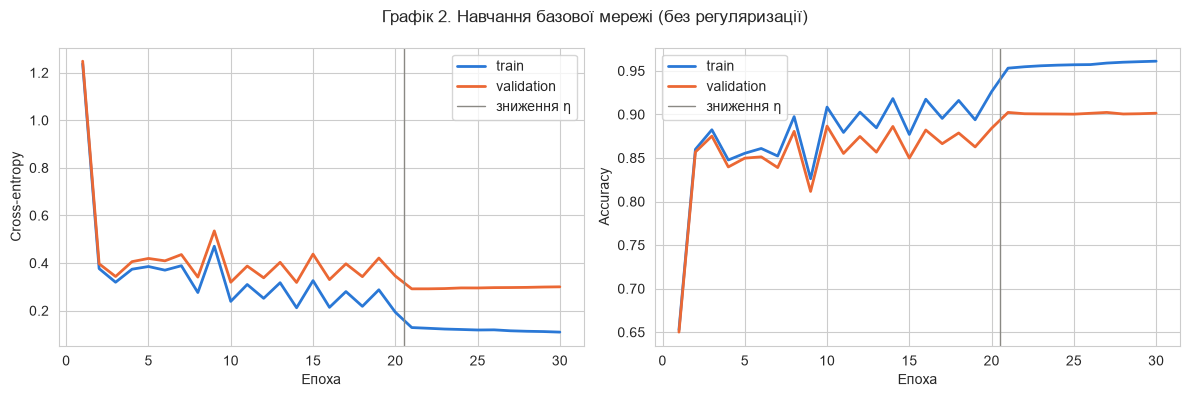

,epoch,train_loss,val_loss,train_acc,val_acc
0,1,1.2374,1.2483,0.6526,0.6501
4,5,0.3854,0.4194,0.8554,0.8498
9,10,0.2390,0.3194,0.9084,0.8866
19,20,0.1935,0.3457,0.9261,0.8841
29,30,0.1098,0.3001,0.9611,0.9014


Час навчання: 55 с; найкраща val accuracy 0.9023 на епосі 21


In [4]:
@dataclass(frozen=True)
class Regularization:
    l1: float = 0.0
    l2: float = 0.0
    dropout: float = 0.0
    weight_clip: float | None = None
    grad_clip: float | None = None


def cross_entropy(P: np.ndarray, y_true: np.ndarray) -> float:
    return float(-np.mean(np.log(np.clip(P[np.arange(len(y_true)), y_true], 1e-12, None))))


def accuracy(P: np.ndarray, y_true: np.ndarray) -> float:
    return float(np.mean(P.argmax(axis=1) == y_true))


def penalty(weights: list[np.ndarray], reg: Regularization) -> float:
    l1_term = reg.l1 * sum(np.abs(W).sum() for W in weights)
    l2_term = 0.5 * reg.l2 * sum((W ** 2).sum() for W in weights)
    return float(l1_term + l2_term)


def add_penalty_gradients(grads_W: list[np.ndarray], weights: list[np.ndarray], reg: Regularization) -> list[np.ndarray]:
    return [grad + reg.l1 * np.sign(W) + reg.l2 * W for grad, W in zip(grads_W, weights)]


def global_norm(grads_W: list[np.ndarray], grads_b: list[np.ndarray]) -> float:
    return float(np.sqrt(sum((grad ** 2).sum() for grad in [*grads_W, *grads_b])))


def clip_by_global_norm(grads_W: list[np.ndarray], grads_b: list[np.ndarray], norm: float, max_norm: float) -> tuple[list[np.ndarray], list[np.ndarray]]:
    factor = min(1.0, max_norm / max(norm, 1e-12))
    return [grad * factor for grad in grads_W], [grad * factor for grad in grads_b]


def sgd_step(model: MLP, grads_W: list[np.ndarray], grads_b: list[np.ndarray], learning_rate: float) -> None:
    model.weights = [W - learning_rate * grad for W, grad in zip(model.weights, grads_W)]
    model.biases = [b - learning_rate * grad for b, grad in zip(model.biases, grads_b)]


def clip_weights(model: MLP, limit: float) -> None:
    model.weights = [np.clip(W, -limit, limit) for W in model.weights]


def train_batch(model: MLP, X_batch: np.ndarray, y_batch: np.ndarray, reg: Regularization, learning_rate: float) -> tuple[float, float]:
    P = model.forward(X_batch, training=True)
    grads_W, grads_b = model.backward(y_batch)
    grads_W = add_penalty_gradients(grads_W, model.weights, reg)
    norm = global_norm(grads_W, grads_b)
    if reg.grad_clip is not None:
        grads_W, grads_b = clip_by_global_norm(grads_W, grads_b, norm, reg.grad_clip)
    sgd_step(model, grads_W, grads_b, learning_rate)
    if reg.weight_clip is not None:
        clip_weights(model, reg.weight_clip)
    return cross_entropy(P, y_batch), norm


def learning_rate_at(epoch: int) -> float:
    return LEARNING_RATE if epoch <= LEARNING_RATE_DROP_EPOCH else LEARNING_RATE * LEARNING_RATE_DROP_FACTOR


def fit(
    model: MLP, reg: Regularization, X: np.ndarray, y: np.ndarray, X_valid: np.ndarray, y_valid: np.ndarray, seed: int,
    epochs: int = EPOCHS, batch_size: int = BATCH_SIZE,
) -> pd.DataFrame:
    shuffle_rng = np.random.default_rng([seed, 2])
    rows = []
    for epoch in range(1, epochs + 1):
        order = shuffle_rng.permutation(len(X))
        learning_rate = learning_rate_at(epoch)
        steps = [
            train_batch(model, X[order[start:start + batch_size]], y[order[start:start + batch_size]], reg, learning_rate)
            for start in range(0, len(X), batch_size)
        ]
        batch_losses, norms = map(np.array, zip(*steps))
        P_train, P_valid = model.predict_proba(X), model.predict_proba(X_valid)
        rows.append({
            'epoch': epoch,
            'train_loss': cross_entropy(P_train, y),
            'val_loss': cross_entropy(P_valid, y_valid),
            'train_acc': accuracy(P_train, y),
            'val_acc': accuracy(P_valid, y_valid),
            'batch_loss_std': float(batch_losses.std()),
            'grad_norm_median': float(np.median(norms)),
            'clip_share': float(np.mean(norms > reg.grad_clip)) if reg.grad_clip is not None else 0.0,
        })
    return pd.DataFrame(rows)


def neuron_activity(model: MLP, X: np.ndarray) -> dict:
    maxima = [np.full(size, -np.inf) for size in model.layer_sizes[1:-1]]
    active_counts = [np.zeros(size) for size in model.layer_sizes[1:-1]]
    for start in range(0, len(X), INFERENCE_BATCH):
        model.forward(X[start:start + INFERENCE_BATCH])
        hidden_z = model.z_values[:-1]
        maxima = [np.maximum(current, Z.max(axis=0)) for current, Z in zip(maxima, hidden_z)]
        active_counts = [current + (Z > 0).sum(axis=0) for current, Z in zip(active_counts, hidden_z)]
    return {
        'dead_masks': [layer_max <= 0 for layer_max in maxima],
        'active_share': [counts / len(X) for counts in active_counts],
    }


def weight_statistics(weights: list[np.ndarray], limit: float = 1.0) -> dict:
    values = np.concatenate([W.ravel() for W in weights])
    return {
        'sparsity': 100.0 * float(np.mean(np.abs(values) < SPARSITY_THRESHOLD)),
        'exact_zero': 100.0 * float(np.mean(values == 0.0)),
        'mean_abs': float(np.abs(values).mean()),
        'max_abs': float(np.abs(values).max()),
        'at_limit': int(np.sum(np.abs(values) >= limit)),
    }


def run_experiment(
    name: str, reg: Regularization, seed: int, X: np.ndarray, y: np.ndarray,
    X_valid: np.ndarray, y_valid: np.ndarray, layer_sizes: tuple[int, ...],
) -> dict:
    model = MLP(layer_sizes, seed, dropout_p=reg.dropout)
    started = time.perf_counter()
    history = fit(model, reg, X, y, X_valid, y_valid, seed)
    activity = neuron_activity(model, X)
    last = history.iloc[-1]
    return {
        'name': name,
        'seed': seed,
        'reg': reg,
        'history': history,
        'weights': model.weights,
        'biases': model.biases,
        'dead_by_layer': [int(mask.sum()) for mask in activity['dead_masks']],
        'dead_percent': 100.0 * sum(int(mask.sum()) for mask in activity['dead_masks']) / sum(layer_sizes[1:-1]),
        'active_share_by_layer': [float(share.mean()) for share in activity['active_share']],
        'val_acc': float(last['val_acc']),
        'val_loss': float(last['val_loss']),
        'train_acc': float(last['train_acc']),
        'train_loss': float(last['train_loss']),
        'seconds': time.perf_counter() - started,
        **weight_statistics(model.weights, limit=reg.weight_clip or 1.0),
    }


BASELINE = 'Без регуляризації'
RESULTS = {}
baseline_first_run = run_experiment(BASELINE, Regularization(), SEED, X_train, y_train, X_val, y_val, LAYER_SIZES)
RESULTS[BASELINE] = [baseline_first_run]
baseline_history = baseline_first_run['history']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, metric, label in zip(axes, ['loss', 'acc'], ['Cross-entropy', 'Accuracy']):
    axis.plot(baseline_history['epoch'], baseline_history[f'train_{metric}'], color=MAIN_COLOR, linewidth=2, label='train')
    axis.plot(baseline_history['epoch'], baseline_history[f'val_{metric}'], color=ACCENT_COLOR, linewidth=2, label='validation')
    axis.axvline(LEARNING_RATE_DROP_EPOCH + 0.5, color=NEUTRAL_COLOR, linewidth=1, label='зниження η')
    axis.set_xlabel('Епоха')
    axis.set_ylabel(label)
    axis.legend()
fig.suptitle('Графік 2. Навчання базової мережі (без регуляризації)')
plt.tight_layout()
plt.show()

display(baseline_history[baseline_history['epoch'].isin([1, 5, 10, 20, EPOCHS])][['epoch', 'train_loss', 'val_loss', 'train_acc', 'val_acc']].round(4))
print(f"Час навчання: {baseline_first_run['seconds']:.0f} с; найкраща val accuracy {baseline_history['val_acc'].max():.4f} на епосі {int(baseline_history['val_acc'].idxmax()) + 1}")


### 2.5. Перевірка правильності градієнтів

Аналітичні градієнти порівнюються з центральною різницею $\frac{L(\theta+\varepsilon)-L(\theta-\varepsilon)}{2\varepsilon}$, $\varepsilon=10^{-5}$, для випадково вибраних ваг і зміщень кожного шару. Похибка: $E = \frac{|g_{analytic} - g_{numeric}|}{\max(10^{-8},\ |g_{analytic}| + |g_{numeric}|)}$.

Перевірка виконана на малій мережі та малому батчі для чотирьох режимів: без регуляризації, з L2, з L1 і з Dropout. Для Dropout під час кожного обчислення втрат відтворюється та сама маска, інакше чисельна різниця вимірювала б випадковий шум маски.


In [5]:
EPSILON = 1e-5
CHECK_SIZES = (784, 32, 16, 10)
CHECK_SAMPLES_PER_MATRIX = 10
MAX_ALLOWED_ERROR = 1e-5


def objective(model: MLP, X: np.ndarray, y: np.ndarray, reg: Regularization, dropout_seed: int) -> float:
    model.dropout_rng = np.random.default_rng(dropout_seed)
    P = model.forward(X, training=True)
    return cross_entropy(P, y) + penalty(model.weights, reg)


def analytic_gradients(model: MLP, X: np.ndarray, y: np.ndarray, reg: Regularization, dropout_seed: int) -> tuple[list[np.ndarray], list[np.ndarray]]:
    objective(model, X, y, reg, dropout_seed)
    grads_W, grads_b = model.backward(y)
    return add_penalty_gradients(grads_W, model.weights, reg), grads_b


def numeric_derivative(model: MLP, parameter: np.ndarray, index: tuple[int, ...], X: np.ndarray, y: np.ndarray, reg: Regularization, dropout_seed: int) -> float:
    original = parameter[index]
    parameter[index] = original + EPSILON
    loss_plus = objective(model, X, y, reg, dropout_seed)
    parameter[index] = original - EPSILON
    loss_minus = objective(model, X, y, reg, dropout_seed)
    parameter[index] = original
    return (loss_plus - loss_minus) / (2 * EPSILON)


def relative_error(analytic: float, numeric: float) -> float:
    return abs(analytic - numeric) / max(1e-8, abs(analytic) + abs(numeric))


def gradient_check(reg: Regularization, X: np.ndarray, y: np.ndarray, seed: int = SEED, dropout_seed: int = SEED) -> pd.DataFrame:
    model = MLP(CHECK_SIZES, seed, dropout_p=reg.dropout)
    grads_W, grads_b = analytic_gradients(model, X, y, reg, dropout_seed)
    pick_rng = np.random.default_rng(seed)
    rows = []
    matrices = [('W', layer, model.weights[layer], grads_W[layer]) for layer in range(model.num_layers)]
    vectors = [('b', layer, model.biases[layer], grads_b[layer]) for layer in range(model.num_layers)]
    for kind, layer, parameter, gradient in [*matrices, *vectors]:
        for _ in range(CHECK_SAMPLES_PER_MATRIX):
            index = tuple(int(pick_rng.integers(size)) for size in parameter.shape)
            numeric = numeric_derivative(model, parameter, index, X, y, reg, dropout_seed)
            rows.append({
                'Параметр': f'{kind}[{layer}]{list(index)}',
                'Аналітичний': float(gradient[index]),
                'Чисельний': numeric,
                'E': relative_error(float(gradient[index]), numeric),
            })
    return pd.DataFrame(rows)


X_check, y_check = X_train[:64], y_train[:64]
check_modes = {
    'Без регуляризації': Regularization(),
    'L2 (λ₂ = 0.01)': Regularization(l2=0.01),
    'L1 (λ₁ = 0.001)': Regularization(l1=0.001),
    'Dropout (p = 0.3)': Regularization(dropout=0.3),
}
check_tables = {mode: gradient_check(reg, X_check, y_check) for mode, reg in check_modes.items()}

display(check_tables['Без регуляризації'].groupby(lambda i: i // CHECK_SAMPLES_PER_MATRIX).head(1).reset_index(drop=True))
check_summary = pd.DataFrame([
    {'Режим': mode, 'Перевірено параметрів': len(table), 'Медіана E': table['E'].median(), 'Максимум E': table['E'].max()}
    for mode, table in check_tables.items()
])
display(check_summary.style.format({'Медіана E': '{:.2e}', 'Максимум E': '{:.2e}'}))
assert check_summary['Максимум E'].max() < MAX_ALLOWED_ERROR
print(f'Максимальна похибка в усіх режимах менша за {MAX_ALLOWED_ERROR}')


,Параметр,Аналітичний,Чисельний,E
0,"W[0][394, 28]",-0.005220,-0.005220,1.505345e-09
1,"W[1][23, 14]",0.000000,0.000000,0.000000e+00
2,"W[2][13, 2]",-0.015602,-0.015602,3.955038e-10
3,b[0][19],-0.034153,-0.034153,1.304190e-11
4,b[1][8],0.064232,0.064232,1.304170e-10
5,b[2][3],0.008104,0.008104,3.608966e-10


,Режим,Перевірено параметрів,Медіана E,Максимум E
0,Без регуляризації,60,3.52e-10,2.03e-08
1,L2 (λ₂ = 0.01),60,5.22e-10,1.97e-08
2,L1 (λ₁ = 0.001),60,4.04e-10,1.59e-07
3,Dropout (p = 0.3),60,2.19e-10,1.09e-08


Максимальна похибка в усіх режимах менша за 1e-05


### 2.6. Збереження та відновлення ваг

`save_weights` записує в один `.npz`-файл усі матриці ваг, вектори зміщень і конфігурацію (архітектура, seed і метод ініціалізації, ймовірність Dropout). `load_weights` перевіряє, чи збігається архітектура файлу з архітектурою мережі, а `from_file` створює мережу лише за вмістом файлу.

Перевірка повторює методичку: навчена мережа зберігається, у новий екземпляр із такою самою архітектурою завантажуються ваги, і виходи обох мереж порівнюються на validation та test. Умова коректності: $\max|P_{original} - P_{restored}| < 10^{-7}$.


In [6]:
RESTORE_TOLERANCE = 1e-7


def restored_model(record: dict) -> MLP:
    model = MLP(LAYER_SIZES, record['seed'], dropout_p=record['reg'].dropout)
    model.weights = record['weights']
    model.biases = record['biases']
    return model


original_model = restored_model(baseline_first_run)
X_compare = np.vstack([X_val, X_test])

with tempfile.TemporaryDirectory() as temporary_dir:
    weights_path = Path(temporary_dir) / 'baseline_weights.npz'
    original_model.save_weights(weights_path)
    file_size_mb = weights_path.stat().st_size / 1024 ** 2

    untrained_model = MLP(LAYER_SIZES, seed=SEED + 100)
    new_model = MLP(LAYER_SIZES, seed=SEED + 100)
    new_model.load_weights(weights_path)
    from_file_model = MLP.from_file(weights_path)

    wrong_architecture_rejected = False
    try:
        MLP((784, 32, 10), seed=SEED).load_weights(weights_path)
    except ValueError as error:
        wrong_architecture_rejected = True
        print('Несумісна архітектура:', error)

P_original = original_model.predict_proba(X_compare)
P_untrained = untrained_model.predict_proba(X_compare)
P_restored = new_model.predict_proba(X_compare)
P_from_file = from_file_model.predict_proba(X_compare)

display(pd.DataFrame([
    {
        'Порівняння з оригіналом': label,
        'max |ΔP|': float(np.abs(P_original - P).max()),
        'Збіг передбачених класів': float(np.mean(P_original.argmax(axis=1) == P.argmax(axis=1))),
    }
    for label, P in [
        ('новий екземпляр до завантаження ваг', P_untrained),
        ('новий екземпляр після load_weights', P_restored),
        ('екземпляр із MLP.from_file', P_from_file),
    ]
]))
print(f'Розмір файлу: {file_size_mb:.2f} МБ')
assert np.abs(P_original - P_restored).max() < RESTORE_TOLERANCE
assert np.abs(P_original - P_from_file).max() < RESTORE_TOLERANCE
assert wrong_architecture_rejected


Несумісна архітектура: Архітектура файлу [784, 256, 128, 64, 10] не збігається з [784, 32, 10]


,Порівняння з оригіналом,max |ΔP|,Збіг передбачених класів
0,новий екземпляр до завантаження ваг,0.990415,0.07875
1,новий екземпляр після load_weights,0.000000,1.00000
2,екземпляр із MLP.from_file,0.000000,1.00000


Розмір файлу: 1.85 МБ


## Блок 2. Дослідження впливу регуляризації

### Методика порівняння

Кожен експеримент повторено для трьох значень seed ($46, 47, 48$), бо різниці між методами можуть бути сумірними зі зміною результату від ініціалізації. У таблицях наведено середнє, а для validation accuracy також стандартне відхилення. За однакового seed у всіх методів однакові початкові ваги й порядок батчів, тож порівняння парні. Гістограми побудовано для першого запуску ($\text{seed}=46$).

Показники:

- **Dead, %** — частка нейронів усіх прихованих шарів, для яких $\max_i Z_{ij}^{(l)} \le 0$ на всій тренувальній вибірці (inference, Dropout вимкнено);
- **Sparsity, %** — частка ваг $|W_{ij}| < 0.01$ у всіх матрицях ваг, включно з вихідною;
- **Val. accuracy і Val. loss** — значення на останній епосі, тобто без раннього зупинення.


In [7]:
def run_grid(experiments: dict[str, Regularization], seeds: list[int] = SEEDS) -> None:
    tasks = [
        (name, reg, seed)
        for name, reg in experiments.items()
        for seed in seeds
        if not any(record['seed'] == seed for record in RESULTS.get(name, []))
    ]
    records = Parallel(n_jobs=N_JOBS)(
        delayed(run_experiment)(name, reg, seed, X_train, y_train, X_val, y_val, LAYER_SIZES)
        for name, reg, seed in tasks
    )
    for record in records:
        RESULTS[record['name']] = [*RESULTS.get(record['name'], []), record]
    for name in experiments:
        RESULTS[name] = sorted(RESULTS[name], key=lambda record: record['seed'])


def parameter_label(reg: Regularization) -> str:
    parts = [
        f'λ₁={reg.l1:g}' if reg.l1 else '',
        f'λ₂={reg.l2:g}' if reg.l2 else '',
        f'p={reg.dropout:g}' if reg.dropout else '',
        f'|W|≤{reg.weight_clip:g}' if reg.weight_clip else '',
        f'c={reg.grad_clip:g}' if reg.grad_clip else '',
    ]
    return ', '.join(part for part in parts if part) or '—'


def summary_row(name: str) -> dict:
    records = RESULTS[name]
    frame = pd.DataFrame(records)
    return {
        'Метод': name,
        'Параметри': parameter_label(records[0]['reg']),
        'Dead, %': frame['dead_percent'].mean(),
        'Sparsity, %': frame['sparsity'].mean(),
        'Train acc.': frame['train_acc'].mean(),
        'Val. accuracy': frame['val_acc'].mean(),
        'Val. acc. std': frame['val_acc'].std(ddof=1),
        'Val. loss': frame['val_loss'].mean(),
        'Train − Val': (frame['train_acc'] - frame['val_acc']).mean(),
    }


def summary_table(names: list[str]) -> pd.DataFrame:
    return pd.DataFrame([summary_row(name) for name in names])


TABLE_FORMAT = {
    'Dead, %': '{:.2f}', 'Sparsity, %': '{:.2f}', 'Train acc.': '{:.4f}', 'Val. accuracy': '{:.4f}',
    'Val. acc. std': '{:.4f}', 'Val. loss': '{:.4f}', 'Train − Val': '{:.4f}',
}


def show_summary(names: list[str]) -> None:
    display(summary_table(names).style.format(TABLE_FORMAT).hide(axis='index'))


def dead_table(names: list[str]) -> pd.DataFrame:
    hidden_labels = [f'Шар {index + 1} ({size})' for index, size in enumerate(HIDDEN_SIZES)]
    rows = []
    for name in names:
        counts = np.array([record['dead_by_layer'] for record in RESULTS[name]])
        means = counts.mean(axis=0)
        rows.append({
            'Метод': name,
            **{label: f'{value:.1f} ({100 * value / size:.1f}%)' for label, value, size in zip(hidden_labels, means, HIDDEN_SIZES)},
            'Усього, %': round(float(np.mean([record['dead_percent'] for record in RESULTS[name]])), 2),
        })
    return pd.DataFrame(rows)


def best_by_validation(names: list[str]) -> str:
    return max(names, key=lambda name: np.mean([record['val_acc'] for record in RESULTS[name]]))


def hidden_values(weights: list[np.ndarray]) -> np.ndarray:
    return np.concatenate([W.ravel() for W in weights[:-1]])


HIST_RANGE = (-0.6, 0.6)
HIST_BINS = 120


def histogram_outline(axis: plt.Axes, values: np.ndarray, color: str, label: str, linewidth: float = 1.5) -> None:
    axis.hist(values, bins=HIST_BINS, range=HIST_RANGE, density=True, histtype='step', color=color, linewidth=linewidth, label=label)


def plot_weight_grid(names: list[str], title: str, columns: int = 3) -> None:
    baseline_values = hidden_values(RESULTS[BASELINE][0]['weights'])
    rows = int(np.ceil(len(names) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4.4 * columns, 3.0 * rows), sharex=True, sharey=True, squeeze=False)
    for axis in axes.ravel()[len(names):]:
        axis.set_visible(False)
    for axis, name in zip(axes.ravel(), names):
        histogram_outline(axis, baseline_values, NEUTRAL_COLOR, 'без регуляризації', linewidth=1.2)
        histogram_outline(axis, hidden_values(RESULTS[name][0]['weights']), MAIN_COLOR, 'метод')
        axis.set_yscale('log')
        axis.set_title(name, fontsize=10)
        axis.set_xlabel('Вага')
    for axis in axes[:, 0]:
        axis.set_ylabel('Щільність (лог.)')
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_validation_curves(names: list[str], title: str) -> None:
    fig, axes = plt.subplots(1, len(names), figsize=(3.4 * len(names), 3.2), sharey=True, squeeze=False)
    for axis, name in zip(axes[0], names):
        history = RESULTS[name][0]['history']
        axis.plot(history['epoch'], history['train_acc'], color=MAIN_COLOR, linewidth=2, label='train')
        axis.plot(history['epoch'], history['val_acc'], color=ACCENT_COLOR, linewidth=2, label='validation')
        axis.set_title(name, fontsize=10)
        axis.set_xlabel('Епоха')
    axes[0, 0].set_ylabel('Accuracy')
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


### 3.1. Базовий експеримент

Мережа без регуляризації є точкою порівняння для всіх наступних методів. Початковий стан показано для seed = 46: за He частка майже нульових ваг вже ненульова, бо $\mathcal{N}(0, 2/n_{in})$ має відчутну масу біля нуля.


Метод,Параметри,"Dead, %","Sparsity, %",Train acc.,Val. accuracy,Val. acc. std,Val. loss,Train − Val
Без регуляризації,—,0.00,12.08,0.9595,0.9013,0.0004,0.3060,0.0582


,Матриця,"Sparsity до навчання, %","Sparsity після навчання, %",Std до навчання,Std після навчання,Max |W| після навчання
0,W[0] (784×256),15.7486,13.1198,0.0505,0.0630,0.4664
1,W[1] (256×128),8.9386,7.6691,0.0887,0.1022,0.4128
2,W[2] (128×64),6.5918,5.3589,0.1243,0.1500,0.6717
3,W[3] (64×10),5.6250,2.3438,0.1687,0.3378,1.0677


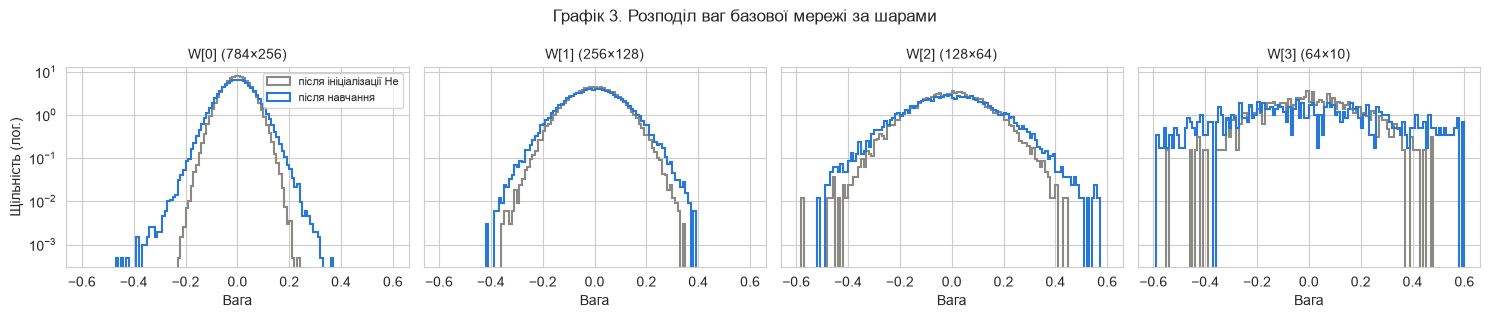

In [8]:
run_grid({BASELINE: Regularization()})
show_summary([BASELINE])

initial_model = MLP(LAYER_SIZES, SEED)
trained_weights = RESULTS[BASELINE][0]['weights']
layer_names = [f'W[{index}] ({W.shape[0]}×{W.shape[1]})' for index, W in enumerate(trained_weights)]
display(pd.DataFrame([
    {
        'Матриця': label,
        'Sparsity до навчання, %': 100 * float(np.mean(np.abs(initial) < SPARSITY_THRESHOLD)),
        'Sparsity після навчання, %': 100 * float(np.mean(np.abs(trained) < SPARSITY_THRESHOLD)),
        'Std до навчання': float(initial.std()),
        'Std після навчання': float(trained.std()),
        'Max |W| після навчання': float(np.abs(trained).max()),
    }
    for label, initial, trained in zip(layer_names, initial_model.weights, trained_weights)
]).round(4))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for axis, label, initial, trained in zip(axes, layer_names, initial_model.weights, trained_weights):
    histogram_outline(axis, initial.ravel(), NEUTRAL_COLOR, 'після ініціалізації He')
    histogram_outline(axis, trained.ravel(), MAIN_COLOR, 'після навчання')
    axis.set_yscale('log')
    axis.set_title(label, fontsize=10)
    axis.set_xlabel('Вага')
axes[0].set_ylabel('Щільність (лог.)')
axes[0].legend(fontsize=8)
fig.suptitle('Графік 3. Розподіл ваг базової мережі за шарами')
plt.tight_layout()
plt.show()


### 3.2. Діагностика мертвих нейронів

Нейрон мертвий, якщо $\max_i Z_{ij}^{(l)} \le 0$ на всій тренувальній вибірці. Перевірка виконується в режимі inference з вимкненим Dropout. Функція `neuron_activity` рахує також, яка частка нейронів шару активується на одному об'єкті в середньому. Так видно різницю між нейроном, неактивним на конкретному об'єкті, і нейроном, мертвим на всій вибірці.

Методичка застерігає, що нейрон, не активований на тренувальній вибірці, не обов'язково мертвий для всього простору даних. Тому мертві на train нейрони окремо перевірено на test.


In [9]:
def dead_on_other_sample(record: dict, X_other: np.ndarray) -> tuple[int, int]:
    model = restored_model(record)
    dead_train = neuron_activity(model, X_train)['dead_masks']
    dead_other = neuron_activity(model, X_other)['dead_masks']
    revived = sum(int((train_mask & ~other_mask).sum()) for train_mask, other_mask in zip(dead_train, dead_other))
    return sum(int(mask.sum()) for mask in dead_train), revived


display(dead_table([BASELINE]))
display(pd.DataFrame([
    {
        'Шар': f'{index + 1} ({size})',
        'Середня частка активних нейронів на об\'єкт, %': round(100 * float(np.mean([record['active_share_by_layer'][index] for record in RESULTS[BASELINE]])), 1),
    }
    for index, size in enumerate(HIDDEN_SIZES)
]))


,Метод,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Усього, %"
0,Без регуляризації,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0


,Шар,"Середня частка активних нейронів на об'єкт, %"
0,1 (256),31.3
1,2 (128),42.5
2,3 (64),48.0


### 3.3. Дослідження L2 регуляризації

$L = L_{CE} + \frac{\lambda_2}{2}\sum_l \|W^{(l)}\|_2^2$, оновлення: $W^{(l)} \leftarrow W^{(l)} - \eta(\nabla_{W^{(l)}} L_{CE} + \lambda_2 W^{(l)})$.


Метод,Параметри,"Dead, %","Sparsity, %",Train acc.,Val. accuracy,Val. acc. std,Val. loss,Train − Val
Без регуляризації,—,0.00,12.08,0.9595,0.9013,0.0004,0.3060,0.0582
L2 λ₂=1e-05,λ₂=1e-05,0.00,12.28,0.9597,0.9011,0.0011,0.3033,0.0586
L2 λ₂=0.0001,λ₂=0.0001,0.00,13.92,0.9564,0.9027,0.0010,0.2923,0.0537
L2 λ₂=0.001,λ₂=0.001,0.15,37.71,0.9322,0.8998,0.0017,0.2758,0.0324
L2 λ₂=0.01,λ₂=0.01,6.03,80.04,0.8642,0.8587,0.0033,0.4057,0.0055
L2 λ₂=0.1,λ₂=0.1,13.69,93.78,0.6918,0.6951,0.0064,0.9284,-0.0033


,Метод,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Усього, %"
0,L2 λ₂=1e-05,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.00
1,L2 λ₂=0.0001,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.00
2,L2 λ₂=0.001,0.0 (0.0%),0.0 (0.0%),0.7 (1.0%),0.15
3,L2 λ₂=0.01,13.0 (5.1%),9.3 (7.3%),4.7 (7.3%),6.03
4,L2 λ₂=0.1,31.3 (12.2%),17.7 (13.8%),12.3 (19.3%),13.69


/var/folders/j2/237jpg197j5cy1hzy0br8b3m0000gn/T/ipykernel_54817/588032082.py:105: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()


/Users/miroslavzizin/IdeaProjects/ml/lab5/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


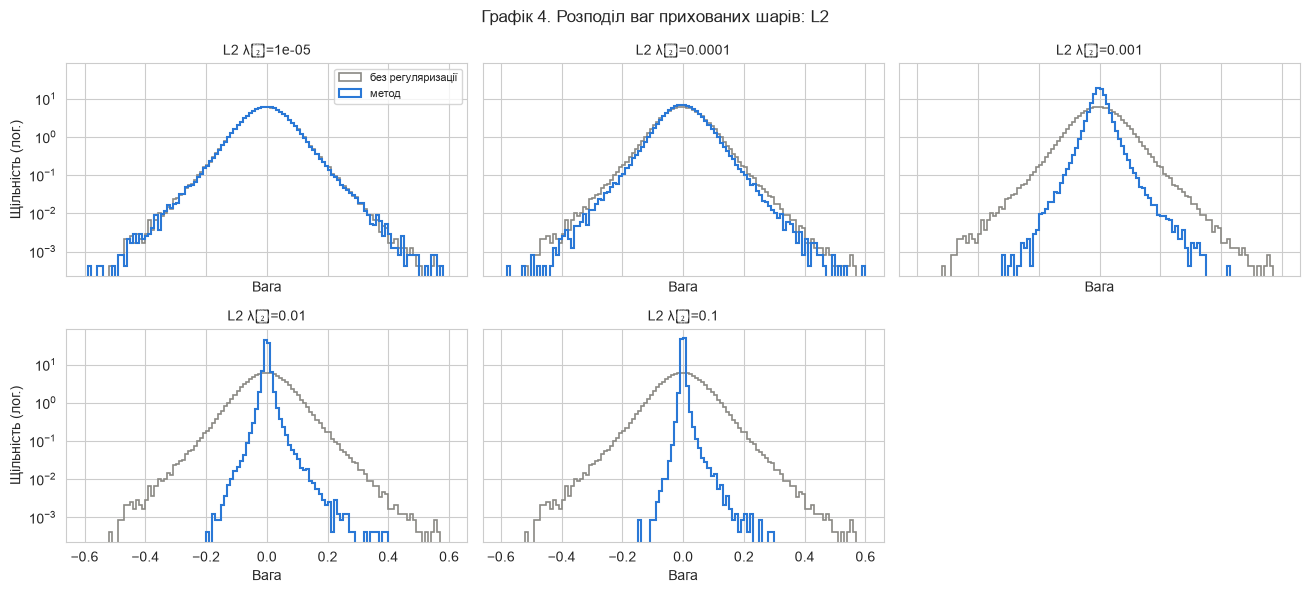

In [10]:
L2_VALUES = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
L2_NAMES = [f'L2 λ₂={value:g}' for value in L2_VALUES]
run_grid({name: Regularization(l2=value) for name, value in zip(L2_NAMES, L2_VALUES)})
show_summary([BASELINE, *L2_NAMES])
display(dead_table(L2_NAMES))
plot_weight_grid(L2_NAMES, 'Графік 4. Розподіл ваг прихованих шарів: L2')


### 3.4. Дослідження L1 регуляризації

$L = L_{CE} + \lambda_1\sum_l \|W^{(l)}\|_1$, градієнт штрафу: $\lambda_1 \operatorname{sign}(W^{(l)})$, у нулі використано субградієнт $0$ (саме так працює `np.sign`).

Додатково виміряно частку точних нулів. Субградієнтний SGD не зобов'язаний занулювати вагу: вона може коливатися біля нуля з амплітудою порядку $\eta\lambda_1$.


Метод,Параметри,"Dead, %","Sparsity, %",Train acc.,Val. accuracy,Val. acc. std,Val. loss,Train − Val
Без регуляризації,—,0.00,12.08,0.9595,0.9013,0.0004,0.3060,0.0582
L1 λ₁=1e-05,λ₁=1e-05,0.00,27.12,0.9561,0.9023,0.0013,0.2937,0.0538
L1 λ₁=0.0001,λ₁=0.0001,6.10,90.41,0.9116,0.8906,0.0006,0.2933,0.0210
L1 λ₁=0.001,λ₁=0.001,33.93,99.51,0.8471,0.8468,0.0055,0.4255,0.0003
L1 λ₁=0.01,λ₁=0.01,32.51,99.92,0.5991,0.5994,0.0567,0.9884,-0.0002


,Метод,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Усього, %"
0,L1 λ₁=1e-05,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.00
1,L1 λ₁=0.0001,25.0 (9.8%),2.0 (1.6%),0.3 (0.5%),6.10
2,L1 λ₁=0.001,88.3 (34.5%),43.0 (33.6%),20.7 (32.3%),33.93
3,L1 λ₁=0.01,77.3 (30.2%),41.0 (32.0%),27.3 (42.7%),32.51


,Метод,"Sparsity, %","Точних нулів, %",Середнє |W|,Max |W|
0,Без регуляризації,12.0823,0.0,0.0567,1.1576
1,L1 λ₁=1e-05,27.1195,0.0,0.0441,1.2236
2,L1 λ₁=0.0001,90.4126,0.0,0.0071,1.5033
3,L1 λ₁=0.001,99.5141,0.0,0.0008,1.6897
4,L1 λ₁=0.01,99.9172,0.0,0.0002,2.4078


/var/folders/j2/237jpg197j5cy1hzy0br8b3m0000gn/T/ipykernel_54817/588032082.py:105: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()


/Users/miroslavzizin/IdeaProjects/ml/lab5/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


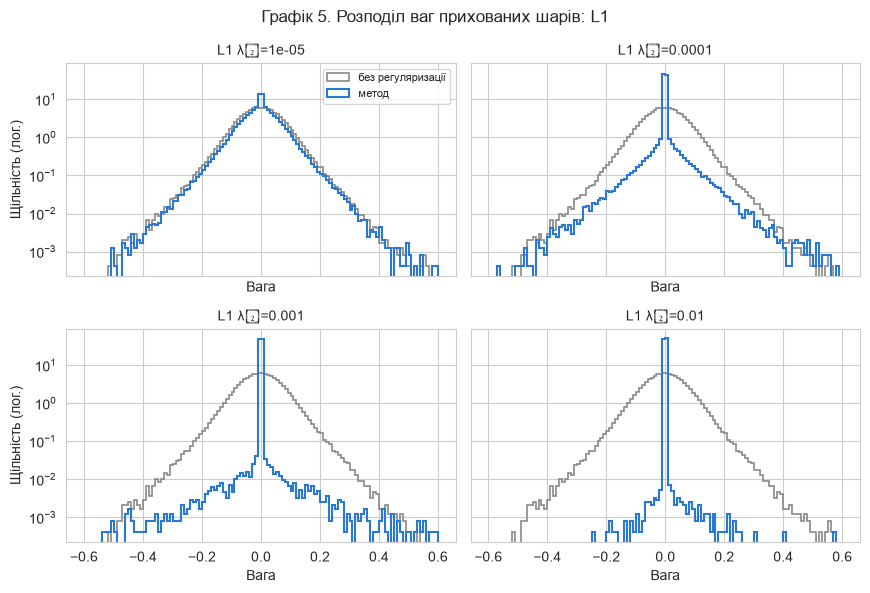

In [11]:
L1_VALUES = [1e-5, 1e-4, 1e-3, 1e-2]
L1_NAMES = [f'L1 λ₁={value:g}' for value in L1_VALUES]
run_grid({name: Regularization(l1=value) for name, value in zip(L1_NAMES, L1_VALUES)})
show_summary([BASELINE, *L1_NAMES])
display(dead_table(L1_NAMES))
display(pd.DataFrame([
    {
        'Метод': name,
        'Sparsity, %': np.mean([record['sparsity'] for record in RESULTS[name]]),
        'Точних нулів, %': np.mean([record['exact_zero'] for record in RESULTS[name]]),
        'Середнє |W|': np.mean([record['mean_abs'] for record in RESULTS[name]]),
        'Max |W|': np.mean([record['max_abs'] for record in RESULTS[name]]),
    }
    for name in [BASELINE, *L1_NAMES]
]).round(4))
plot_weight_grid(L1_NAMES, 'Графік 5. Розподіл ваг прихованих шарів: L1', columns=2)


### 3.5. Дослідження Dropout

Inverted Dropout застосовано до всіх прихованих шарів, $p \in \{0.1, 0.3, 0.5\}$. Під час оцінювання й діагностики мертвих нейронів Dropout вимкнено.


Метод,Параметри,"Dead, %","Sparsity, %",Train acc.,Val. accuracy,Val. acc. std,Val. loss,Train − Val
Без регуляризації,—,0.00,12.08,0.9595,0.9013,0.0004,0.3060,0.0582
Dropout 0.1,p=0.1,0.00,12.19,0.9411,0.9018,0.0020,0.2821,0.0392
Dropout 0.3,p=0.3,0.00,12.35,0.9196,0.8935,0.0012,0.2937,0.0261
Dropout 0.5,p=0.5,0.00,12.40,0.8951,0.8803,0.0011,0.3337,0.0148


,Метод,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Усього, %"
0,Dropout 0.1,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0
1,Dropout 0.3,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0
2,Dropout 0.5,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0


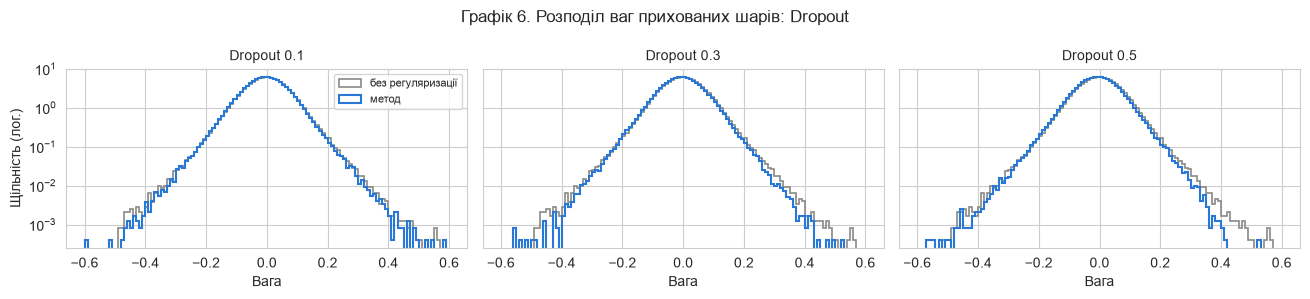

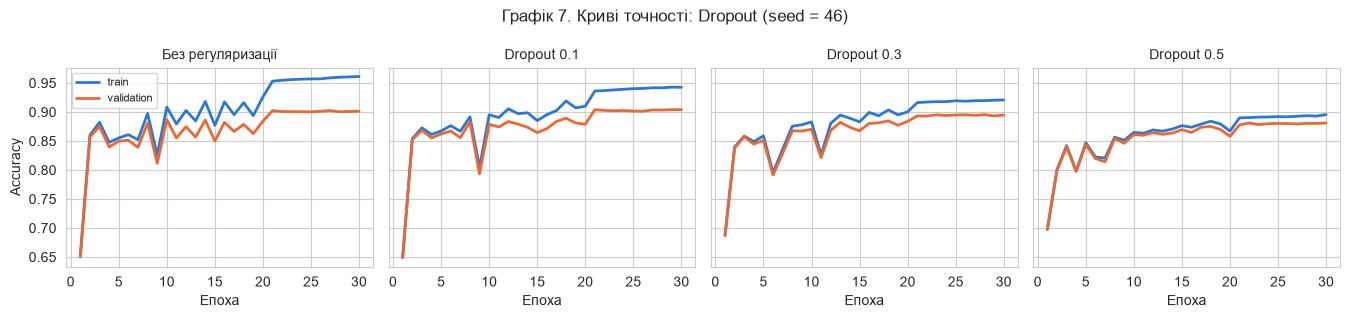

In [12]:
DROPOUT_VALUES = [0.1, 0.3, 0.5]
DROPOUT_NAMES = [f'Dropout {value:g}' for value in DROPOUT_VALUES]
run_grid({name: Regularization(dropout=value) for name, value in zip(DROPOUT_NAMES, DROPOUT_VALUES)})
show_summary([BASELINE, *DROPOUT_NAMES])
display(dead_table(DROPOUT_NAMES))
plot_weight_grid(DROPOUT_NAMES, 'Графік 6. Розподіл ваг прихованих шарів: Dropout')
plot_validation_curves([BASELINE, *DROPOUT_NAMES], 'Графік 7. Криві точності: Dropout (seed = 46)')


### 3.6. Дослідження Weight clipping

Після кожного кроку: $W^{(l)} \leftarrow \operatorname{clip}(W^{(l)}, -1, 1)$. Зміщення не обмежуються.

Обов'язковий за методичкою експеримент має межу $\pm 1$. Щоб побачити дію справді жорсткого обмеження, додано ще межі $\pm 0.1$ і $\pm 0.03$. У порівняльну таблицю розд. 4.1 входить лише варіант $\pm 1$.


Метод,Параметри,"Dead, %","Sparsity, %",Train acc.,Val. accuracy,Val. acc. std,Val. loss,Train − Val
Без регуляризації,—,0.00,12.08,0.9595,0.9013,0.0004,0.3060,0.0582
Weight clipping ±1,|W|≤1,0.00,12.10,0.9586,0.9009,0.0003,0.3074,0.0577
Weight clipping ±0.1,|W|≤0.1,0.15,12.01,0.9215,0.8951,0.0002,0.2909,0.0264
Weight clipping ±0.03,|W|≤0.03,4.54,11.21,0.7084,0.7139,0.0139,0.8137,-0.0055


,Метод,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Усього, %"
0,Weight clipping ±1,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.00
1,Weight clipping ±0.1,0.0 (0.0%),0.0 (0.0%),0.7 (1.0%),0.15
2,Weight clipping ±0.03,0.0 (0.0%),12.3 (9.6%),8.0 (12.5%),4.54


,Метод,Межа,Ваг із |W| ≥ межі (середнє),"Частка, %"
0,Без регуляризації,1.00,2.3333,0.0010
1,Weight clipping ±1,1.00,0.0000,0.0000
2,Weight clipping ±0.1,0.10,1275.6667,0.5265
3,Weight clipping ±0.03,0.03,41024.3333,16.9309


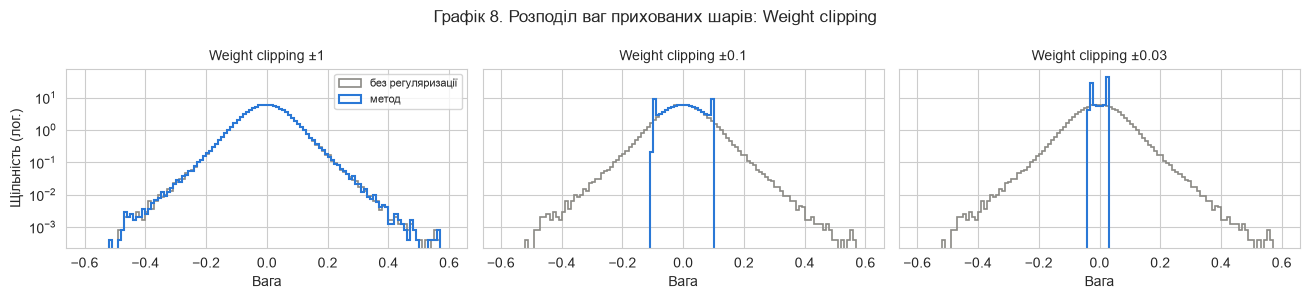

In [13]:
CLIP_LIMITS = [1.0, 0.1, 0.03]
CLIP_NAMES = [f'Weight clipping ±{limit:g}' for limit in CLIP_LIMITS]
run_grid({name: Regularization(weight_clip=limit) for name, limit in zip(CLIP_NAMES, CLIP_LIMITS)})
show_summary([BASELINE, *CLIP_NAMES])
display(dead_table(CLIP_NAMES))

total_weights = sum(W.size for W in RESULTS[BASELINE][0]['weights'])
baseline_exceeding = np.mean([weight_statistics(record['weights'], limit=1.0)['at_limit'] for record in RESULTS[BASELINE]])
display(pd.DataFrame([
    {'Метод': BASELINE, 'Межа': 1.0, 'Ваг із |W| ≥ межі (середнє)': baseline_exceeding, 'Частка, %': 100 * baseline_exceeding / total_weights},
    *[
        {
            'Метод': name,
            'Межа': limit,
            'Ваг із |W| ≥ межі (середнє)': np.mean([record['at_limit'] for record in RESULTS[name]]),
            'Частка, %': 100 * np.mean([record['at_limit'] for record in RESULTS[name]]) / total_weights,
        }
        for name, limit in zip(CLIP_NAMES, CLIP_LIMITS)
    ],
]).round(4))
plot_weight_grid(CLIP_NAMES, 'Графік 8. Розподіл ваг прихованих шарів: Weight clipping')


### 3.7. Дослідження Gradient clipping

Обрізання за глобальною L2-нормою всіх градієнтів: $g_{clipped} = g \cdot \min(1, c / \|g\|_2)$. Стабільність втрат оцінено на епохах 11–20, де крок ще великий ($\eta = 0.1$), а нестабільність найпомітніша. Показники усереднено за трьома запусками: стандартне відхилення втрат батчів в межах епохи, середня абсолютна зміна validation loss між сусідніми епохами, медіанна норма градієнта й частка кроків, на яких спрацював кліпінг.


Метод,Параметри,"Dead, %","Sparsity, %",Train acc.,Val. accuracy,Val. acc. std,Val. loss,Train − Val
Без регуляризації,—,0.00,12.08,0.9595,0.9013,0.0004,0.3060,0.0582
Gradient clipping c=0.1,c=0.1,0.89,14.29,0.8774,0.8696,0.0019,0.3757,0.0078
Gradient clipping c=0.5,c=0.5,0.22,13.80,0.9301,0.8943,0.0018,0.2978,0.0358
Gradient clipping c=1,c=1,0.07,13.03,0.9546,0.9019,0.0023,0.2969,0.0527
Gradient clipping c=5,c=5,0.00,12.09,0.9601,0.9025,0.0022,0.3032,0.0576


,Метод,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Усього, %"
0,Gradient clipping c=0.1,0.0 (0.0%),0.7 (0.5%),3.3 (5.2%),0.89
1,Gradient clipping c=0.5,0.0 (0.0%),0.0 (0.0%),1.0 (1.6%),0.22
2,Gradient clipping c=1,0.0 (0.0%),0.0 (0.0%),0.3 (0.5%),0.07
3,Gradient clipping c=5,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.00


,Метод,Std втрат батчів,Середня |Δ val loss| між епохами,Медіана ‖g‖,"Кроків із кліпінгом, %"
0,Без регуляризації,0.0757,0.1102,1.4025,0.0000
1,Gradient clipping c=0.1,0.1006,0.0084,3.2436,100.0000
2,Gradient clipping c=0.5,0.0858,0.0192,2.2956,100.0000
3,Gradient clipping c=1,0.0789,0.0238,1.8203,97.5874
4,Gradient clipping c=5,0.0757,0.0798,1.4019,0.0341


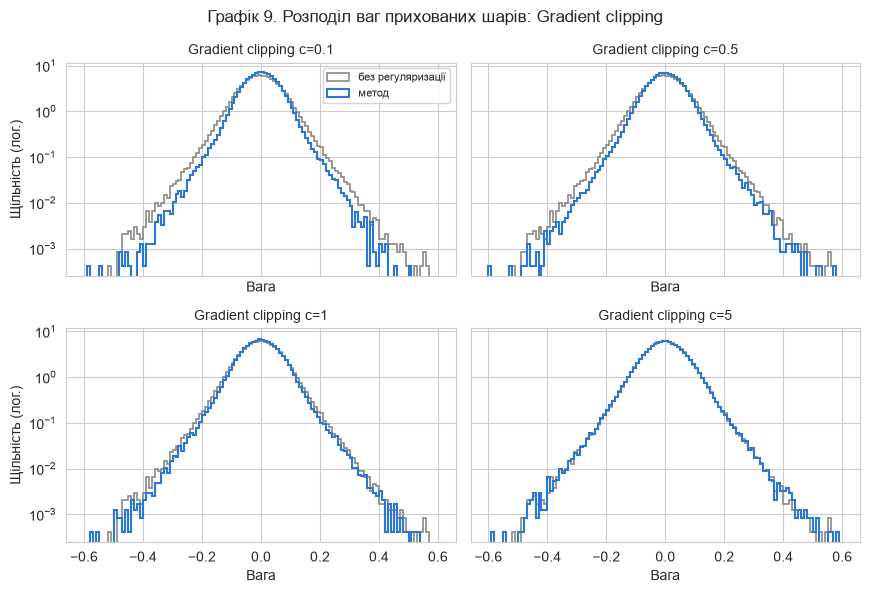

In [14]:
GRAD_CLIP_VALUES = [0.1, 0.5, 1.0, 5.0]
GRAD_CLIP_NAMES = [f'Gradient clipping c={value:g}' for value in GRAD_CLIP_VALUES]
STABILITY_FIRST_EPOCH = 11


def stability_row(name: str) -> dict:
    windows = [
        record['history'].assign(val_loss_change=lambda frame: frame['val_loss'].diff().abs())
        .query('@STABILITY_FIRST_EPOCH <= epoch <= @LEARNING_RATE_DROP_EPOCH')
        for record in RESULTS[name]
    ]
    return {
        'Метод': name,
        'Std втрат батчів': np.mean([window['batch_loss_std'].mean() for window in windows]),
        'Середня |Δ val loss| між епохами': np.mean([window['val_loss_change'].mean() for window in windows]),
        'Медіана ‖g‖': np.mean([window['grad_norm_median'].mean() for window in windows]),
        'Кроків із кліпінгом, %': 100 * np.mean([window['clip_share'].mean() for window in windows]),
    }


run_grid({name: Regularization(grad_clip=value) for name, value in zip(GRAD_CLIP_NAMES, GRAD_CLIP_VALUES)})
show_summary([BASELINE, *GRAD_CLIP_NAMES])
display(dead_table(GRAD_CLIP_NAMES))
display(pd.DataFrame([stability_row(name) for name in [BASELINE, *GRAD_CLIP_NAMES]]).round(4))
plot_weight_grid(GRAD_CLIP_NAMES, 'Графік 9. Розподіл ваг прихованих шарів: Gradient clipping', columns=2)


### 3.8. Комбінована регуляризація

Обов'язкова комбінація: L2 разом із Dropout $p = 0.2$. Значення $\lambda_2^*$ — найкраще за validation із розд. 3.3. Для коректного порівняння окремо навчено Dropout $p = 0.2$ без L2, а також комбінації із $\lambda_2^*/10$ і $10\lambda_2^*$, щоб перевірити, чи настає надмірне обмеження моделі.


Обране λ₂* = 0.0001


Метод,Параметри,"Dead, %","Sparsity, %",Train acc.,Val. accuracy,Val. acc. std,Val. loss,Train − Val
Без регуляризації,—,0.00,12.08,0.9595,0.9013,0.0004,0.3060,0.0582
L2 λ₂=0.0001,λ₂=0.0001,0.00,13.92,0.9564,0.9027,0.0010,0.2923,0.0537
Dropout 0.2,p=0.2,0.00,12.24,0.9294,0.8986,0.0016,0.2846,0.0309
L2 λ₂=1e-05 + Dropout 0.2,"λ₂=1e-05, p=0.2",0.00,12.38,0.9291,0.8980,0.0016,0.2848,0.0311
L2 λ₂=0.0001 + Dropout 0.2,"λ₂=0.0001, p=0.2",0.00,14.02,0.9296,0.8984,0.0014,0.2819,0.0312
L2 λ₂=0.001 + Dropout 0.2,"λ₂=0.001, p=0.2",0.07,37.17,0.9194,0.8955,0.0026,0.2850,0.0239


,Метод,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Усього, %"
0,L2 λ₂=1e-05 + Dropout 0.2,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.00
1,L2 λ₂=0.0001 + Dropout 0.2,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.00
2,L2 λ₂=0.001 + Dropout 0.2,0.0 (0.0%),0.0 (0.0%),0.3 (0.5%),0.07


/var/folders/j2/237jpg197j5cy1hzy0br8b3m0000gn/T/ipykernel_54817/588032082.py:105: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()


/Users/miroslavzizin/IdeaProjects/ml/lab5/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


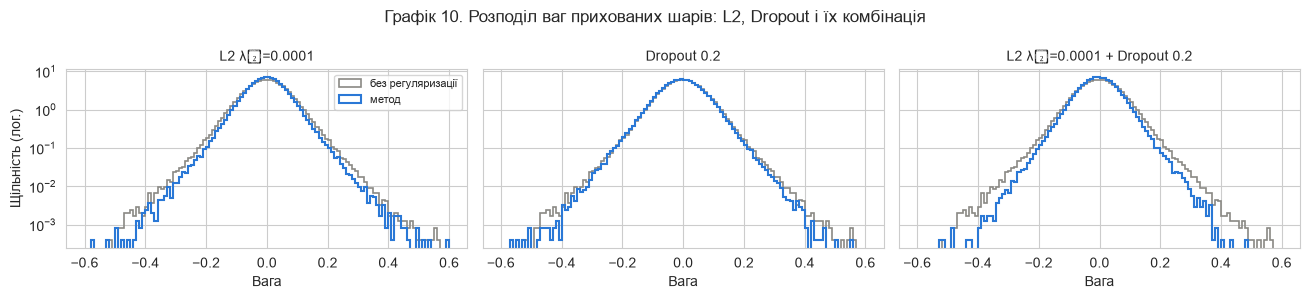

In [15]:
BEST_L2_NAME = best_by_validation(L2_NAMES)
BEST_L2 = RESULTS[BEST_L2_NAME][0]['reg'].l2
COMBO_DROPOUT = 0.2
DROPOUT_ONLY_NAME = f'Dropout {COMBO_DROPOUT:g}'
COMBINED_NAME = f'L2 λ₂={BEST_L2:g} + Dropout {COMBO_DROPOUT:g}'
WEAKER_COMBINED_NAME = f'L2 λ₂={BEST_L2 / 10:g} + Dropout {COMBO_DROPOUT:g}'
STRONGER_COMBINED_NAME = f'L2 λ₂={BEST_L2 * 10:g} + Dropout {COMBO_DROPOUT:g}'
COMBO_NAMES = [WEAKER_COMBINED_NAME, COMBINED_NAME, STRONGER_COMBINED_NAME]

run_grid({
    DROPOUT_ONLY_NAME: Regularization(dropout=COMBO_DROPOUT),
    WEAKER_COMBINED_NAME: Regularization(l2=BEST_L2 / 10, dropout=COMBO_DROPOUT),
    COMBINED_NAME: Regularization(l2=BEST_L2, dropout=COMBO_DROPOUT),
    STRONGER_COMBINED_NAME: Regularization(l2=BEST_L2 * 10, dropout=COMBO_DROPOUT),
})
print('Обране λ₂* =', BEST_L2)
show_summary([BASELINE, BEST_L2_NAME, DROPOUT_ONLY_NAME, *COMBO_NAMES])
display(dead_table(COMBO_NAMES))
plot_weight_grid([BEST_L2_NAME, DROPOUT_ONLY_NAME, COMBINED_NAME], 'Графік 10. Розподіл ваг прихованих шарів: L2, Dropout і їх комбінація')


## 4. Аналіз та порівняння результатів

### 4.1. Порівняльна таблиця

Для методів із кількома значеннями коефіцієнта в рядок винесено найкраще за validation. Використані значення наведено в стовпці «Параметри». Для dropout рядки задані методичкою, для weight clipping обов'язкова межа $\pm 1$.


In [16]:
BEST_L1_NAME = best_by_validation(L1_NAMES)
BEST_GRAD_CLIP_NAME = best_by_validation(GRAD_CLIP_NAMES)
MAIN_NAMES = [BASELINE, BEST_L1_NAME, BEST_L2_NAME, *DROPOUT_NAMES, CLIP_NAMES[0], BEST_GRAD_CLIP_NAME, COMBINED_NAME]
main_table = summary_table(MAIN_NAMES)
display(main_table.style.format(TABLE_FORMAT).hide(axis='index'))
display(dead_table(MAIN_NAMES))

baseline_scores = np.array([record['val_acc'] for record in RESULTS[BASELINE]])
display(pd.DataFrame([
    {
        'Метод': name,
        'Середня різниця Val. acc. з базовою': float(np.mean(np.array([record['val_acc'] for record in RESULTS[name]]) - baseline_scores)),
        'Найменша різниця у запуску': float(np.min(np.array([record['val_acc'] for record in RESULTS[name]]) - baseline_scores)),
        'Найбільша різниця у запуску': float(np.max(np.array([record['val_acc'] for record in RESULTS[name]]) - baseline_scores)),
    }
    for name in MAIN_NAMES[1:]
]).round(4))


Метод,Параметри,"Dead, %","Sparsity, %",Train acc.,Val. accuracy,Val. acc. std,Val. loss,Train − Val
Без регуляризації,—,0.00,12.08,0.9595,0.9013,0.0004,0.3060,0.0582
L1 λ₁=1e-05,λ₁=1e-05,0.00,27.12,0.9561,0.9023,0.0013,0.2937,0.0538
L2 λ₂=0.0001,λ₂=0.0001,0.00,13.92,0.9564,0.9027,0.0010,0.2923,0.0537
Dropout 0.1,p=0.1,0.00,12.19,0.9411,0.9018,0.0020,0.2821,0.0392
Dropout 0.3,p=0.3,0.00,12.35,0.9196,0.8935,0.0012,0.2937,0.0261
Dropout 0.5,p=0.5,0.00,12.40,0.8951,0.8803,0.0011,0.3337,0.0148
Weight clipping ±1,|W|≤1,0.00,12.10,0.9586,0.9009,0.0003,0.3074,0.0577
Gradient clipping c=5,c=5,0.00,12.09,0.9601,0.9025,0.0022,0.3032,0.0576
L2 λ₂=0.0001 + Dropout 0.2,"λ₂=0.0001, p=0.2",0.00,14.02,0.9296,0.8984,0.0014,0.2819,0.0312


,Метод,Шар 1 (256),Шар 2 (128),Шар 3 (64),"Усього, %"
0,Без регуляризації,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0
1,L1 λ₁=1e-05,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0
2,L2 λ₂=0.0001,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0
3,Dropout 0.1,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0
4,Dropout 0.3,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0
5,Dropout 0.5,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0
6,Weight clipping ±1,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0
7,Gradient clipping c=5,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0
8,L2 λ₂=0.0001 + Dropout 0.2,0.0 (0.0%),0.0 (0.0%),0.0 (0.0%),0.0


,Метод,Середня різниця Val. acc. з базовою,Найменша різниця у запуску,Найбільша різниця у запуску
0,L1 λ₁=1e-05,0.0011,-0.0006,0.0022
1,L2 λ₂=0.0001,0.0014,0.0002,0.0024
2,Dropout 0.1,0.0006,-0.0007,0.0027
3,Dropout 0.3,-0.0078,-0.0088,-0.0065
4,Dropout 0.5,-0.0210,-0.0226,-0.0201
5,Weight clipping ±1,-0.0003,-0.0005,-0.0001
6,Gradient clipping c=5,0.0013,-0.0011,0.0040
7,L2 λ₂=0.0001 + Dropout 0.2,-0.0028,-0.0038,-0.0014


### 4.2. Розподіл ваг

На спільному графіку порівняно початковий розподіл He, розподіл після навчання без регуляризації та розподіл після кожного методу. Гістограми охоплюють ваги всіх прихованих шарів, вісь $y$ логарифмічна.


/var/folders/j2/237jpg197j5cy1hzy0br8b3m0000gn/T/ipykernel_54817/1491077023.py:21: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/j2/237jpg197j5cy1hzy0br8b3m0000gn/T/ipykernel_54817/1491077023.py:21: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()


/Users/miroslavzizin/IdeaProjects/ml/lab5/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/miroslavzizin/IdeaProjects/ml/lab5/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


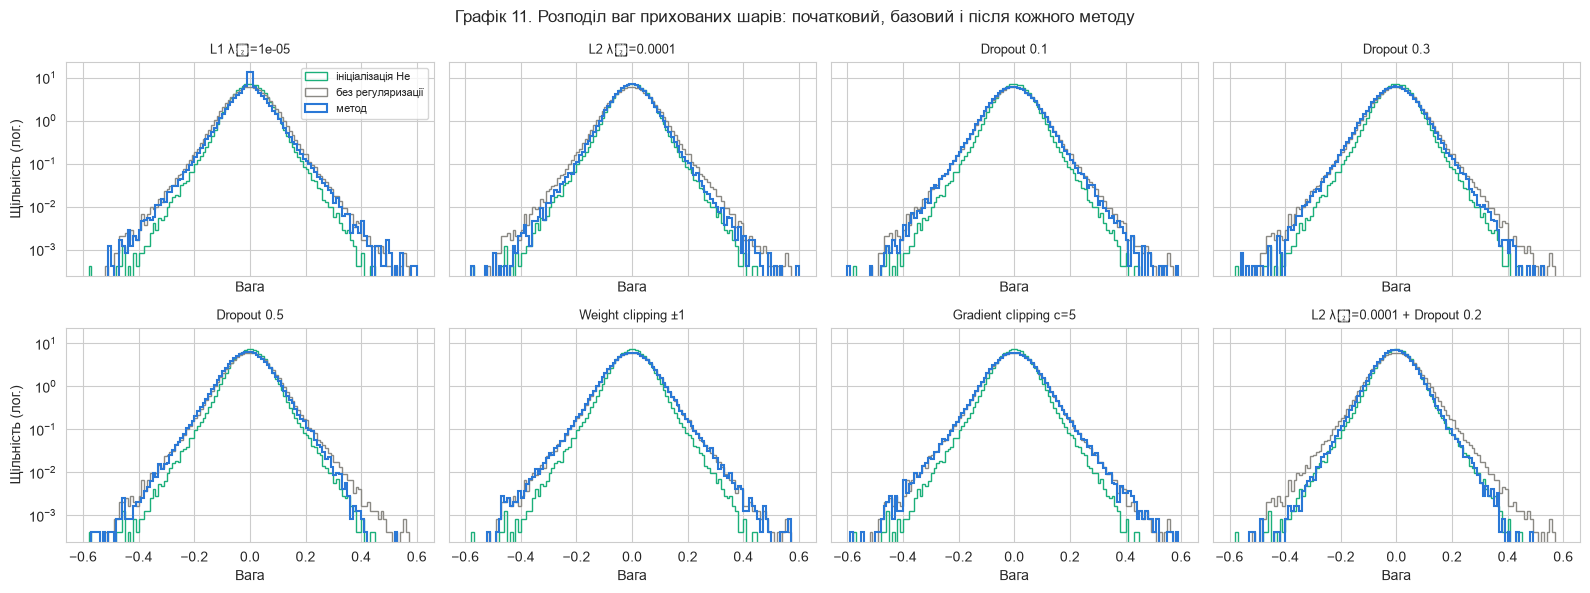

/var/folders/j2/237jpg197j5cy1hzy0br8b3m0000gn/T/ipykernel_54817/1491077023.py:36: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/j2/237jpg197j5cy1hzy0br8b3m0000gn/T/ipykernel_54817/1491077023.py:36: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()


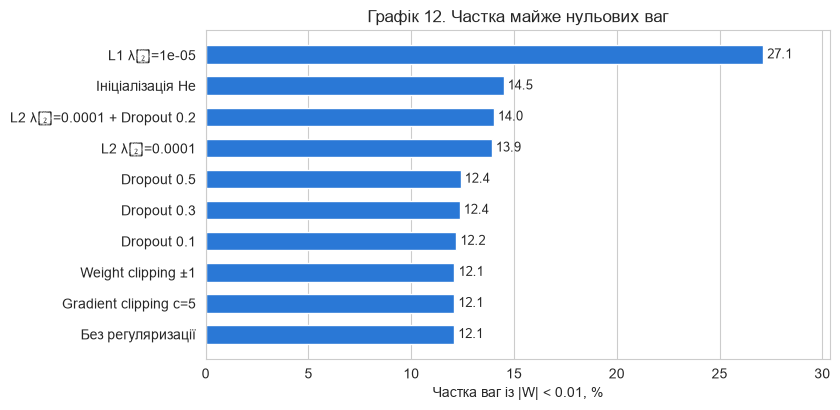

In [17]:
initial_values = hidden_values(MLP(LAYER_SIZES, SEED).weights)
baseline_values = hidden_values(RESULTS[BASELINE][0]['weights'])
compared_names = MAIN_NAMES[1:]

columns = 4
rows = int(np.ceil(len(compared_names) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(16, 3.0 * rows), sharex=True, sharey=True, squeeze=False)
for axis in axes.ravel()[len(compared_names):]:
    axis.set_visible(False)
for axis, name in zip(axes.ravel(), compared_names):
    histogram_outline(axis, initial_values, THIRD_COLOR, 'ініціалізація He', linewidth=1.0)
    histogram_outline(axis, baseline_values, NEUTRAL_COLOR, 'без регуляризації', linewidth=1.0)
    histogram_outline(axis, hidden_values(RESULTS[name][0]['weights']), MAIN_COLOR, 'метод')
    axis.set_yscale('log')
    axis.set_title(name, fontsize=9)
    axis.set_xlabel('Вага')
for axis in axes[:, 0]:
    axis.set_ylabel('Щільність (лог.)')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Графік 11. Розподіл ваг прихованих шарів: початковий, базовий і після кожного методу')
plt.tight_layout()
plt.show()

near_zero = pd.DataFrame(
    [{'Метод': 'Ініціалізація He', 'Sparsity, %': 100 * float(np.mean(np.abs(np.concatenate([W.ravel() for W in MLP(LAYER_SIZES, SEED).weights])) < SPARSITY_THRESHOLD))}]
    + [{'Метод': name, 'Sparsity, %': np.mean([record['sparsity'] for record in RESULTS[name]])} for name in MAIN_NAMES]
).sort_values('Sparsity, %')

fig, axis = plt.subplots(figsize=(8.5, 4.2))
bars = axis.barh(near_zero['Метод'], near_zero['Sparsity, %'], color=MAIN_COLOR, height=0.6)
axis.bar_label(bars, fmt='%.1f', padding=3, fontsize=9)
axis.set_xlabel('Частка ваг із |W| < 0.01, %')
axis.set_title('Графік 12. Частка майже нульових ваг')
axis.grid(axis='y', visible=False)
axis.set_xlim(0, near_zero['Sparsity, %'].max() * 1.12)
plt.tight_layout()
plt.show()


### 4.3. Залежність мертвих нейронів від точності

Кожна точка — окремий експеримент (середнє за трьома запусками). На лівій панелі всі конфігурації, на правій — збільшена область із точністю вище 0.8. Коефіцієнт Спірмена обчислено за всіма конфігураціями.


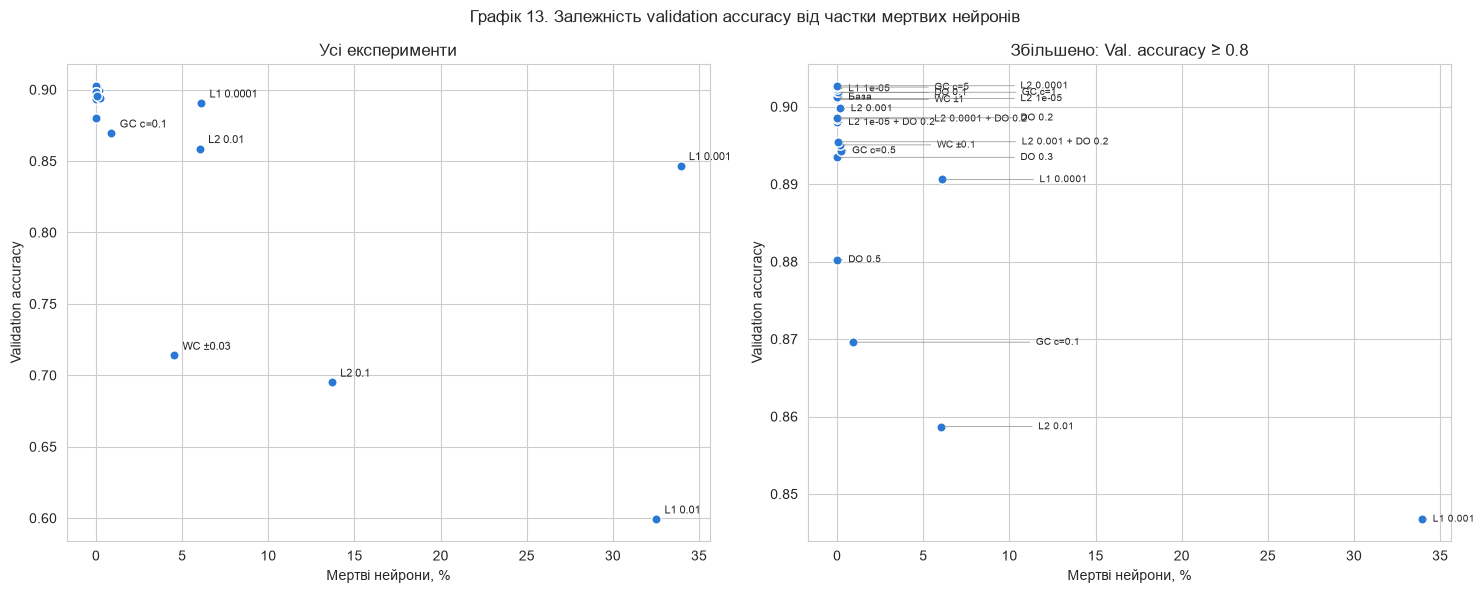

,Пара показників,Конфігурацій,ρ Спірмена,p-value
0,Dead % — Val. accuracy,24,-0.7563,0.0000
1,Sparsity % — Val. accuracy,24,-0.4243,0.0388
2,Sparsity % — Dead %,24,0.6006,0.0019


Конфігурацій без жодного мертвого нейрона: 12; їх Val. accuracy від 0.8803 до 0.9027
Конфігурацій із мертвими нейронами: 12


Метод,Параметри,"Sparsity, %","Dead, %",Val. accuracy
Weight clipping ±0.03,|W|≤0.03,11.21,4.54,0.7139
Weight clipping ±0.1,|W|≤0.1,12.01,0.15,0.8951
Без регуляризації,—,12.08,0.00,0.9013
Gradient clipping c=5,c=5,12.09,0.00,0.9025
Weight clipping ±1,|W|≤1,12.10,0.00,0.9009
Dropout 0.1,p=0.1,12.19,0.00,0.9018
Dropout 0.2,p=0.2,12.24,0.00,0.8986
L2 λ₂=1e-05,λ₂=1e-05,12.28,0.00,0.9011
Dropout 0.3,p=0.3,12.35,0.00,0.8935
L2 λ₂=1e-05 + Dropout 0.2,"λ₂=1e-05, p=0.2",12.38,0.00,0.8980


In [18]:
ALL_NAMES = list(RESULTS)
scatter_data = summary_table(ALL_NAMES)
SHORT_LABELS = {BASELINE: 'База'}


def short_label(name: str) -> str:
    return (
        SHORT_LABELS.get(name, name)
        .replace('Gradient clipping ', 'GC ')
        .replace('Weight clipping ', 'WC ')
        .replace('Dropout ', 'DO ')
        .replace(' λ₁=', ' ')
        .replace(' λ₂=', ' ')
    )


ZOOM_ACCURACY = 0.8
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(scatter_data['Dead, %'], scatter_data['Val. accuracy'], color=MAIN_COLOR, s=45, edgecolor='white', linewidth=1)
for _, row in scatter_data[scatter_data['Dead, %'] > 0.5].iterrows():
    axes[0].annotate(short_label(row['Метод']), (row['Dead, %'], row['Val. accuracy']), textcoords='offset points', xytext=(6, 4), fontsize=8)
axes[0].set_title('Усі експерименти')

zoomed = scatter_data[scatter_data['Val. accuracy'] >= ZOOM_ACCURACY].sort_values('Val. accuracy').reset_index(drop=True)
axes[1].scatter(zoomed['Dead, %'], zoomed['Val. accuracy'], color=MAIN_COLOR, s=45, edgecolor='white', linewidth=1)
for index, row in zoomed.iterrows():
    axes[1].annotate(
        short_label(row['Метод']), (row['Dead, %'], row['Val. accuracy']),
        textcoords='offset points', xytext=(8 + 62 * (index % 3), 0), fontsize=7.5, va='center',
        arrowprops={'arrowstyle': '-', 'color': NEUTRAL_COLOR, 'linewidth': 0.5},
    )
axes[1].set_title(f'Збільшено: Val. accuracy ≥ {ZOOM_ACCURACY}')
for axis in axes:
    axis.set_xlabel('Мертві нейрони, %')
    axis.set_ylabel('Validation accuracy')
fig.suptitle('Графік 13. Залежність validation accuracy від частки мертвих нейронів')
plt.tight_layout()
plt.show()


def spearman_row(label: str, first: str, second: str, frame: pd.DataFrame) -> dict:
    result = stats.spearmanr(frame[first], frame[second])
    return {'Пара показників': label, 'Конфігурацій': len(frame), 'ρ Спірмена': result.statistic, 'p-value': result.pvalue}


with_dead = scatter_data[scatter_data['Dead, %'] > 0]
without_dead = scatter_data[scatter_data['Dead, %'] == 0]
display(pd.DataFrame([
    spearman_row('Dead % — Val. accuracy', 'Dead, %', 'Val. accuracy', scatter_data),
    spearman_row('Sparsity % — Val. accuracy', 'Sparsity, %', 'Val. accuracy', scatter_data),
    spearman_row('Sparsity % — Dead %', 'Sparsity, %', 'Dead, %', scatter_data),
]).round(4))

print(f'Конфігурацій без жодного мертвого нейрона: {len(without_dead)}; їх Val. accuracy від {without_dead["Val. accuracy"].min():.4f} до {without_dead["Val. accuracy"].max():.4f}')
print(f'Конфігурацій із мертвими нейронами: {len(with_dead)}')

balance_view = scatter_data.sort_values('Sparsity, %')[['Метод', 'Параметри', 'Sparsity, %', 'Dead, %', 'Val. accuracy']]
display(balance_view.style.format({'Sparsity, %': '{:.2f}', 'Dead, %': '{:.2f}', 'Val. accuracy': '{:.4f}'}).hide(axis='index'))


### 4.4. Дослідження залежності регуляризації від якості

**Дослідницьке питання:** чи завжди збільшення сили регуляризації покращує узагальнювальну здатність нейронної мережі?

На кожній панелі показано train і validation accuracy за зростання сили методу (зліва направо). Лінія базової мережі дає точку відліку.


/var/folders/j2/237jpg197j5cy1hzy0br8b3m0000gn/T/ipykernel_54817/502914618.py:20: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/j2/237jpg197j5cy1hzy0br8b3m0000gn/T/ipykernel_54817/502914618.py:20: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
/Users/miroslavzizin/IdeaProjects/ml/lab5/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/miroslavzizin/IdeaProjects/ml/lab5/.venv/lib/python3.11/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


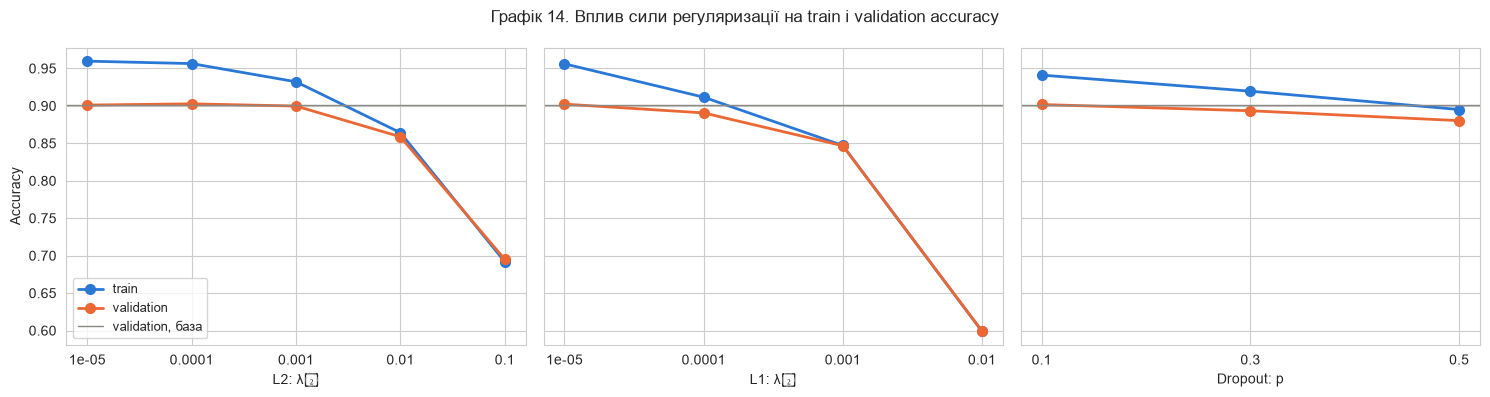

,Метод,Train acc.,Val. accuracy,Train − Val,Val. loss,"Dead, %","Sparsity, %",Стан
0,L2 λ₂=1e-05,0.9597,0.9011,0.0586,0.3033,0.0000,12.2770,у межах шуму
1,L2 λ₂=0.0001,0.9564,0.9027,0.0537,0.2923,0.0000,13.9174,менше перенавчання
2,L2 λ₂=0.001,0.9322,0.8998,0.0324,0.2758,0.1488,37.7087,недонавчання
3,L2 λ₂=0.01,0.8642,0.8587,0.0055,0.4057,6.0268,80.0364,недонавчання
4,L2 λ₂=0.1,0.6918,0.6951,-0.0033,0.9284,13.6905,93.7782,недонавчання
5,L1 λ₁=1e-05,0.9561,0.9023,0.0538,0.2937,0.0000,27.1195,менше перенавчання
6,L1 λ₁=0.0001,0.9116,0.8906,0.0210,0.2933,6.1012,90.4126,недонавчання
7,L1 λ₁=0.001,0.8471,0.8468,0.0003,0.4255,33.9286,99.5141,недонавчання
8,L1 λ₁=0.01,0.5991,0.5994,-0.0002,0.9884,32.5149,99.9172,недонавчання
9,Dropout 0.1,0.9411,0.9018,0.0392,0.2821,0.0000,12.1905,менше перенавчання


,Метод,Середнє |W|,"Майже нульових ваг, %","Точних нулів, %","Активних нейронів на об'єкт, %","Мертвих нейронів, %",Val. accuracy
0,Без регуляризації,0.0567,12.0918,0.0,40.2335,0.0000,0.9014
1,L2 λ₂=0.0001,0.0497,13.9548,0.0,42.1330,0.0000,0.9038
2,L1 λ₁=1e-05,0.0442,27.0850,0.0,41.9064,0.0000,0.9036
3,L1 λ₁=0.01,0.0002,99.9228,0.0,66.3750,29.9107,0.6450


,Метод,Мертвих на train,З них активувалися на test
0,L1 λ₁=1e-05,0,0
1,L1 λ₁=0.01,134,0
2,L2 λ₂=0.1,57,0


In [19]:
strength_groups = [
    ('L2: λ₂', L2_VALUES, L2_NAMES),
    ('L1: λ₁', L1_VALUES, L1_NAMES),
    ('Dropout: p', DROPOUT_VALUES, DROPOUT_NAMES),
]
baseline_val_mean = np.mean([record['val_acc'] for record in RESULTS[BASELINE]])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for axis, (label, values, names) in zip(axes, strength_groups):
    group = summary_table(names)
    positions = np.arange(len(values))
    axis.plot(positions, group['Train acc.'], color=MAIN_COLOR, linewidth=2, marker='o', markersize=7, label='train')
    axis.plot(positions, group['Val. accuracy'], color=ACCENT_COLOR, linewidth=2, marker='o', markersize=7, label='validation')
    axis.axhline(baseline_val_mean, color=NEUTRAL_COLOR, linewidth=1, label='validation, база')
    axis.set_xticks(positions, [f'{value:g}' for value in values])
    axis.set_xlabel(label)
axes[0].set_ylabel('Accuracy')
axes[0].legend(fontsize=9)
fig.suptitle('Графік 14. Вплив сили регуляризації на train і validation accuracy')
plt.tight_layout()
plt.show()


def classify_fit(row: pd.Series, baseline_row: dict) -> str:
    if row['Val. accuracy'] > baseline_row['Val. accuracy'] + baseline_row['Val. acc. std'] and row['Train − Val'] < baseline_row['Train − Val']:
        return 'менше перенавчання'
    if row['Train acc.'] < baseline_row['Train acc.'] and row['Val. accuracy'] < baseline_row['Val. accuracy'] - baseline_row['Val. acc. std']:
        return 'недонавчання'
    return 'у межах шуму'


baseline_row = summary_row(BASELINE)
strength_table = summary_table([*L2_NAMES, *L1_NAMES, *DROPOUT_NAMES, CLIP_NAMES[1], CLIP_NAMES[2]])
strength_table['Стан'] = [classify_fit(row, baseline_row) for _, row in strength_table.iterrows()]
display(strength_table[['Метод', 'Train acc.', 'Val. accuracy', 'Train − Val', 'Val. loss', 'Dead, %', 'Sparsity, %', 'Стан']].round(4))

sparsest_name = max(L2_NAMES + L1_NAMES, key=lambda name: np.mean([record['sparsity'] for record in RESULTS[name]]))
concept_rows = []
for name in [BASELINE, BEST_L2_NAME, BEST_L1_NAME, sparsest_name]:
    record = RESULTS[name][0]
    concept_rows.append({
        'Метод': name,
        'Середнє |W|': record['mean_abs'],
        'Майже нульових ваг, %': record['sparsity'],
        'Точних нулів, %': record['exact_zero'],
        'Активних нейронів на об\'єкт, %': 100 * float(np.mean(record['active_share_by_layer'])),
        'Мертвих нейронів, %': record['dead_percent'],
        'Val. accuracy': record['val_acc'],
    })
display(pd.DataFrame(concept_rows).round(4))

revival_rows = []
for name in [BEST_L1_NAME, sparsest_name, L2_NAMES[-1]]:
    dead_total, revived = dead_on_other_sample(RESULTS[name][0], X_test)
    revival_rows.append({'Метод': name, 'Мертвих на train': dead_total, 'З них активувалися на test': revived})
display(pd.DataFrame(revival_rows))


### Фінальна оцінка на тестовій вибірці

Коефіцієнти вже обрані за validation, тому test використано лише тут, для незалежної оцінки методів із таблиці 4.1.


In [20]:
test_rows = []
for name in MAIN_NAMES:
    scores = [accuracy(restored_model(record).predict_proba(X_test), y_test) for record in RESULTS[name]]
    test_rows.append({
        'Метод': name,
        'Параметри': parameter_label(RESULTS[name][0]['reg']),
        'Val. accuracy': np.mean([record['val_acc'] for record in RESULTS[name]]),
        'Test accuracy': np.mean(scores),
        'Test std': np.std(scores, ddof=1),
    })
display(pd.DataFrame(test_rows).round(4))


,Метод,Параметри,Val. accuracy,Test accuracy,Test std
0,Без регуляризації,—,0.9013,0.8927,0.0015
1,L1 λ₁=1e-05,λ₁=1e-05,0.9023,0.8946,0.0013
2,L2 λ₂=0.0001,λ₂=0.0001,0.9027,0.8953,0.0011
3,Dropout 0.1,p=0.1,0.9018,0.8935,0.0012
4,Dropout 0.3,p=0.3,0.8935,0.8858,0.0015
5,Dropout 0.5,p=0.5,0.8803,0.8707,0.0007
6,Weight clipping ±1,|W|≤1,0.9009,0.8926,0.0022
7,Gradient clipping c=5,c=5,0.9025,0.8940,0.0022
8,L2 λ₂=0.0001 + Dropout 0.2,"λ₂=0.0001, p=0.2",0.8984,0.8902,0.0013
